<a id='import'></a>
## Step 1 | Import Libraries

In [ ]:
# ===================== Install Extra Libraries =====================
!pip install -q xgboost imbalanced-learn

# ===================== Import Libraries =====================
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score
)
from scipy.stats import randint, uniform
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import RFECV
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, accuracy_score
)

from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE

plt.rcParams['figure.dpi'] = 110
sns.set(style='darkgrid')

<a id='load'></a>
## Step 2 | Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

hd = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/dataset/heart_disease_dataset.csv")

Mounted at /content/drive


<a id='overview'></a>
## Step 3 | Dataset Overview

In [ ]:
# ===================== Dataset Shape =====================
print('Rows, Columns:', hd.shape)

Rows, Columns: (10000, 21)


In [ ]:
# ===================== First 5 Rows =====================
hd.head()

,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No


In [ ]:
# ===================== Dataset Info =====================
hd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Age                   9971 non-null   float64
 1   Gender                9981 non-null   object 
 2   Blood Pressure        9981 non-null   float64
 3   Cholesterol Level     9970 non-null   float64
 4   Exercise Habits       9975 non-null   object 
 5   Smoking               9975 non-null   object 
 6   Family Heart Disease  9979 non-null   object 
 7   Diabetes              9970 non-null   object 
 8   BMI                   9978 non-null   float64
 9   High Blood Pressure   9974 non-null   object 
 10  Low HDL Cholesterol   9975 non-null   object 
 11  High LDL Cholesterol  9974 non-null   object 
 12  Alcohol Consumption   7414 non-null   object 
 13  Stress Level          9978 non-null   object 
 14  Sleep Hours           9975 non-null   float64
 15  Sugar Consumption   

In [ ]:
# ===================== Check & Handle Duplicate Records =====================
n_dupes = hd.duplicated().sum()
print("Duplicate Records found:", n_dupes)

if n_dupes > 0:
    hd = hd.drop_duplicates().reset_index(drop=True)
    print("Duplicates dropped. New shape:", hd.shape)
else:
    print("No duplicates to drop.")

Duplicate Records found: 0
No duplicates to drop.


In [ ]:
# ===================== Check Missing Values =====================
missing = (hd.isnull().sum().sort_values(ascending=False))
print("====== Total Missing Value ======")
print(missing)

====== Total Missing Value ======
Alcohol Consumption     2586
Diabetes                  30
Sugar Consumption         30
Cholesterol Level         30
Age                       29
Triglyceride Level        26
CRP Level                 26
High LDL Cholesterol      26
High Blood Pressure       26
Low HDL Cholesterol       25
Sleep Hours               25
Exercise Habits           25
Smoking                   25
Fasting Blood Sugar       22
BMI                       22
Stress Level              22
Family Heart Disease      21
Homocysteine Level        20
Blood Pressure            19
Gender                    19
Heart Disease Status       0
dtype: int64


In [ ]:
# ============ Separate Numerical and Categorical Columns ============
# Numerical Columns
numeric_features = hd.select_dtypes(include=['int64', 'float64']).columns
print(numeric_features)

print('\n')

# Categorical Columns
categorical_features = hd.select_dtypes(include=['object']).columns
print(categorical_features)

Index(['Age', 'Blood Pressure', 'Cholesterol Level', 'BMI', 'Sleep Hours',
       'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level',
       'Homocysteine Level'],
      dtype='object')


Index(['Gender', 'Exercise Habits', 'Smoking', 'Family Heart Disease',
       'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol',
       'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level',
       'Sugar Consumption', 'Heart Disease Status'],
      dtype='object')


In [ ]:
# ========== Outlier Detection (diagnostic only — no rows removed) ==========
Q1 = hd[numeric_features].quantile(0.25)
Q3 = hd[numeric_features].quantile(0.75)
IQR = Q3 - Q1

outlier_counts = ((hd[numeric_features] < (Q1 - 1.5 * IQR)) |
                  (hd[numeric_features] > (Q3 + 1.5 * IQR))).sum()

outlier_counts = outlier_counts.reset_index()
outlier_counts.columns = ['Feature', 'Outlier Count']

outlier_counts

,Feature,Outlier Count
0,Age,0
1,Blood Pressure,0
2,Cholesterol Level,0
3,BMI,0
4,Sleep Hours,0
5,Triglyceride Level,0
6,Fasting Blood Sugar,0
7,CRP Level,0
8,Homocysteine Level,0


In [ ]:
# ===================== Summary Statistics for Numeric Features =====================
hd[numeric_features].describe()

,Age,Blood Pressure,Cholesterol Level,BMI,Sleep Hours,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level
count,9971.000000,9981.000000,9970.000000,9978.000000,9975.000000,9974.000000,9978.000000,9974.000000,9980.000000
mean,49.296259,149.757740,225.425577,29.077269,6.991329,250.734409,120.142213,7.472201,12.456271
std,18.193970,17.572969,43.575809,6.307098,1.753195,87.067226,23.584011,4.340248,4.323426
min,18.000000,120.000000,150.000000,18.002837,4.000605,100.000000,80.000000,0.003647,5.000236
25%,34.000000,134.000000,187.000000,23.658075,5.449866,176.000000,99.000000,3.674126,8.723334
50%,49.000000,150.000000,226.000000,29.079492,7.003252,250.000000,120.000000,7.472164,12.409395
75%,65.000000,165.000000,263.000000,34.520015,8.531577,326.000000,141.000000,11.255592,16.140564
max,80.000000,180.000000,300.000000,39.996954,9.999952,400.000000,160.000000,14.997087,19.999037


In [ ]:
# ===================== Summary Statistics for Categorical Features =====================
hd[categorical_features].describe()

,Gender,Exercise Habits,Smoking,Family Heart Disease,Diabetes,High Blood Pressure,Low HDL Cholesterol,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sugar Consumption,Heart Disease Status
count,9981,9975,9975,9979,9970,9974,9975,9974,7414,9978,9970,10000
unique,2,3,2,2,2,2,2,2,3,3,3,2
top,Male,High,Yes,No,No,Yes,Yes,No,Medium,Medium,Low,No
freq,5003,3372,5123,5004,5018,5022,5000,5036,2500,3387,3390,8000


<a id='eda'></a>
## Step 4 | Exploratory Data Analysis

In [ ]:
hd_eda = hd.copy()

Heart Disease Status
No     8000
Yes    2000
Name: count, dtype: int64


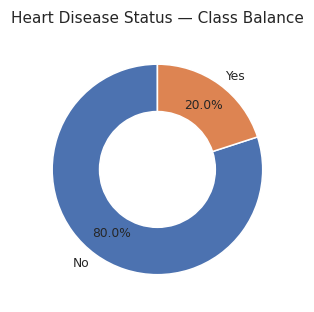

In [ ]:
# ===================== Target Class Balance =====================
target_counts = hd['Heart Disease Status'].value_counts()
print(target_counts)

plt.figure(figsize=(3.5, 3))

plt.pie(
    target_counts.values,
    labels=target_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    labeldistance=1.1,
    wedgeprops={'edgecolor': 'white', 'width': 0.45},
    textprops={'fontsize': 8}
)

plt.title('Heart Disease Status — Class Balance', fontsize=10, pad=10)
plt.tight_layout()
plt.show()

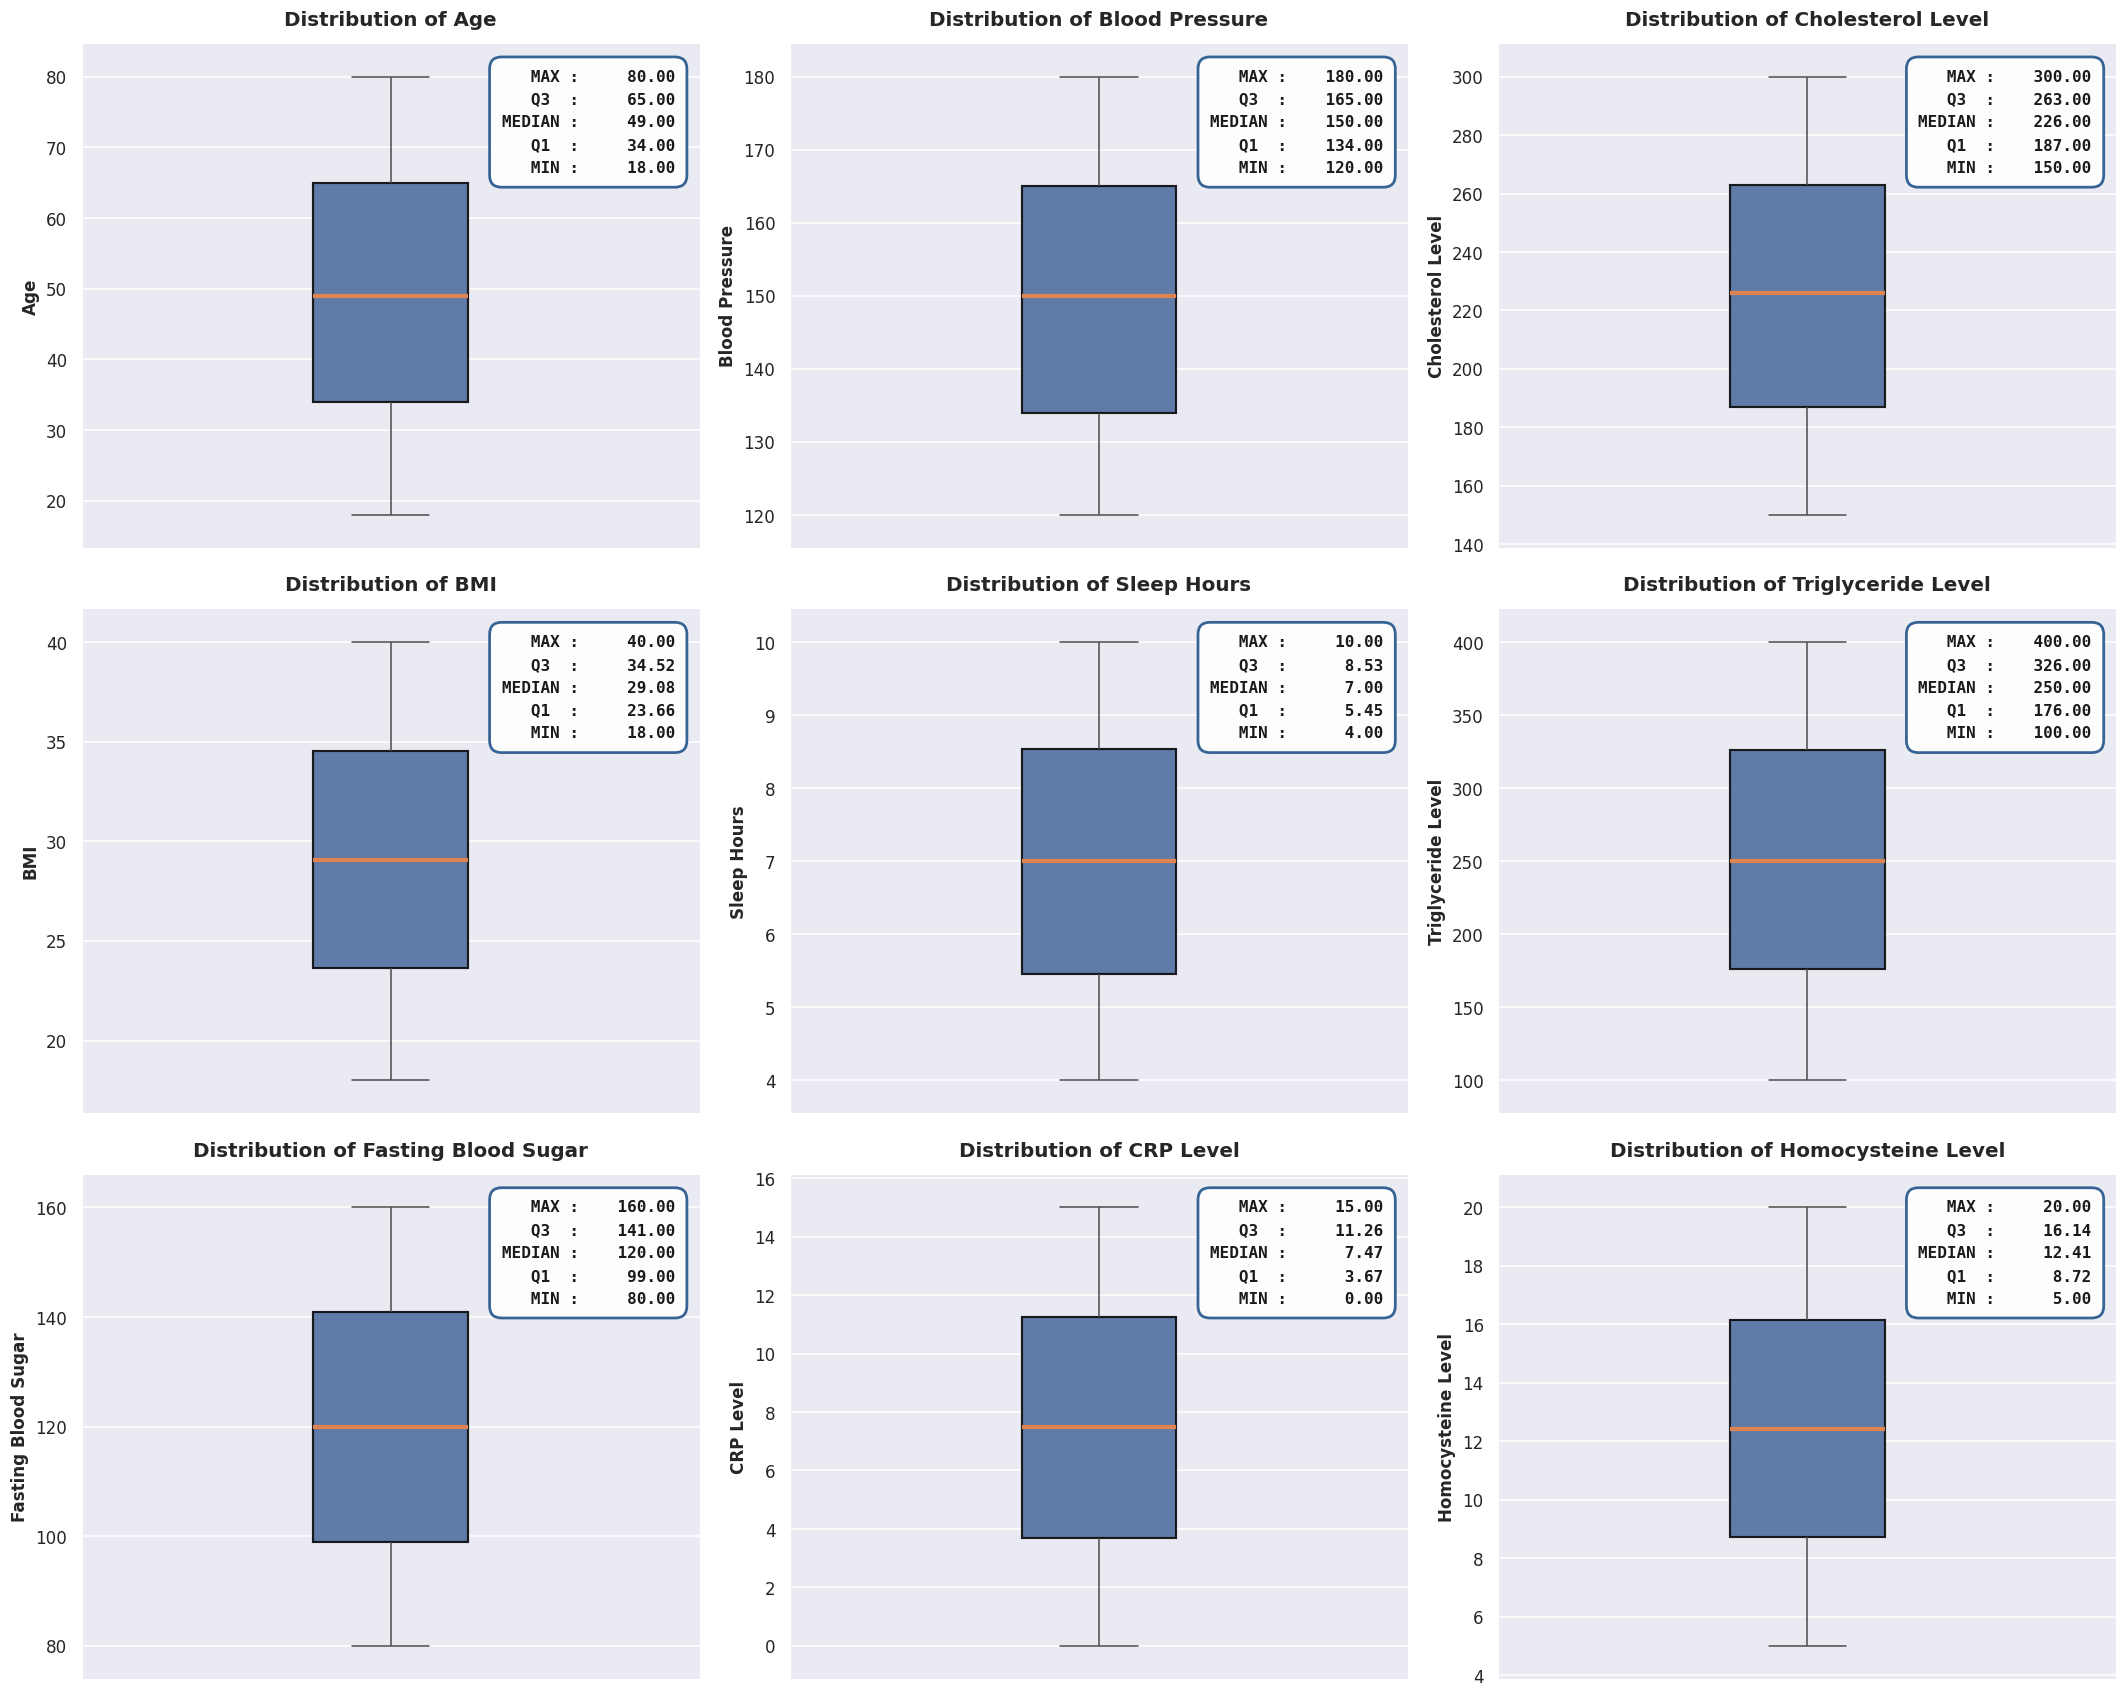

In [ ]:
# ===================== Boxplots: Numeric Feature Distributions =====================
n_cols = 3
n_rows = int(np.ceil(len(numeric_features) / n_cols))

# Expanded figure width to make room for larger stat cards beside boxplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5 * n_cols, 5.2 * n_rows))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    ax = axes[i]
    data = hd_eda[feature].dropna()

    # 1. Base Boxplot offset to the left side (x=-0.2) to make room for stats on the right
    sns.boxplot(
        y=data,
        ax=ax,
        color="#4C72B0",
        width=0.3,
        boxprops=dict(alpha=0.95, edgecolor="#111111", linewidth=1.4),
        medianprops=dict(color="#DD8452", linewidth=2.8),
        showfliers=False,
    )

    # 2. Dynamic Y-limits with comfortable padding
    y_min, y_max = data.min(), data.max()
    y_margin = (y_max - y_min) * 0.15 if y_max != y_min else 1.0
    ax.set_ylim(y_min - y_margin * 0.5, y_max + y_margin * 0.5)
    ax.set_xlim(-0.6, 0.6)

    # 3. Compute 5-Number Summary Statistics
    min_val = y_min
    max_val = y_max
    q1_val = data.quantile(0.25)
    median_val = data.median()
    q3_val = data.quantile(0.75)

    # Fixed-width aligned text formatting with monospace font for crisp readability
    stats_text = (
        f"   MAX : {max_val:>9.2f}\n"
        f"   Q3  : {q3_val:>9.2f}\n"
        f"MEDIAN : {median_val:>9.2f}\n"
        f"   Q1  : {q1_val:>9.2f}\n"
        f"   MIN : {min_val:>9.2f}"
    )

    # 4. Large, styled details card in top-right position
    ax.text(
        0.96,
        0.95,
        stats_text,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10.5,
        fontfamily="monospace",
        fontweight="bold",
        color="#1a1a1a",
        linespacing=1.65,
        bbox=dict(
            boxstyle="round,pad=0.75",
            facecolor="#ffffff",
            edgecolor="#2b5c8f",
            linewidth=1.8,
            alpha=0.95,
        ),
    )

    # 5. Fine-tuned labels and layout borders
    ax.set_title(
        f"Distribution of {feature}", fontsize=13, fontweight="bold", pad=12
    )
    ax.set_ylabel(feature, fontsize=11, fontweight="bold")
    ax.set_xticks([])
    sns.despine(ax=ax, bottom=True)

# Remove unused axes
for j in range(len(numeric_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

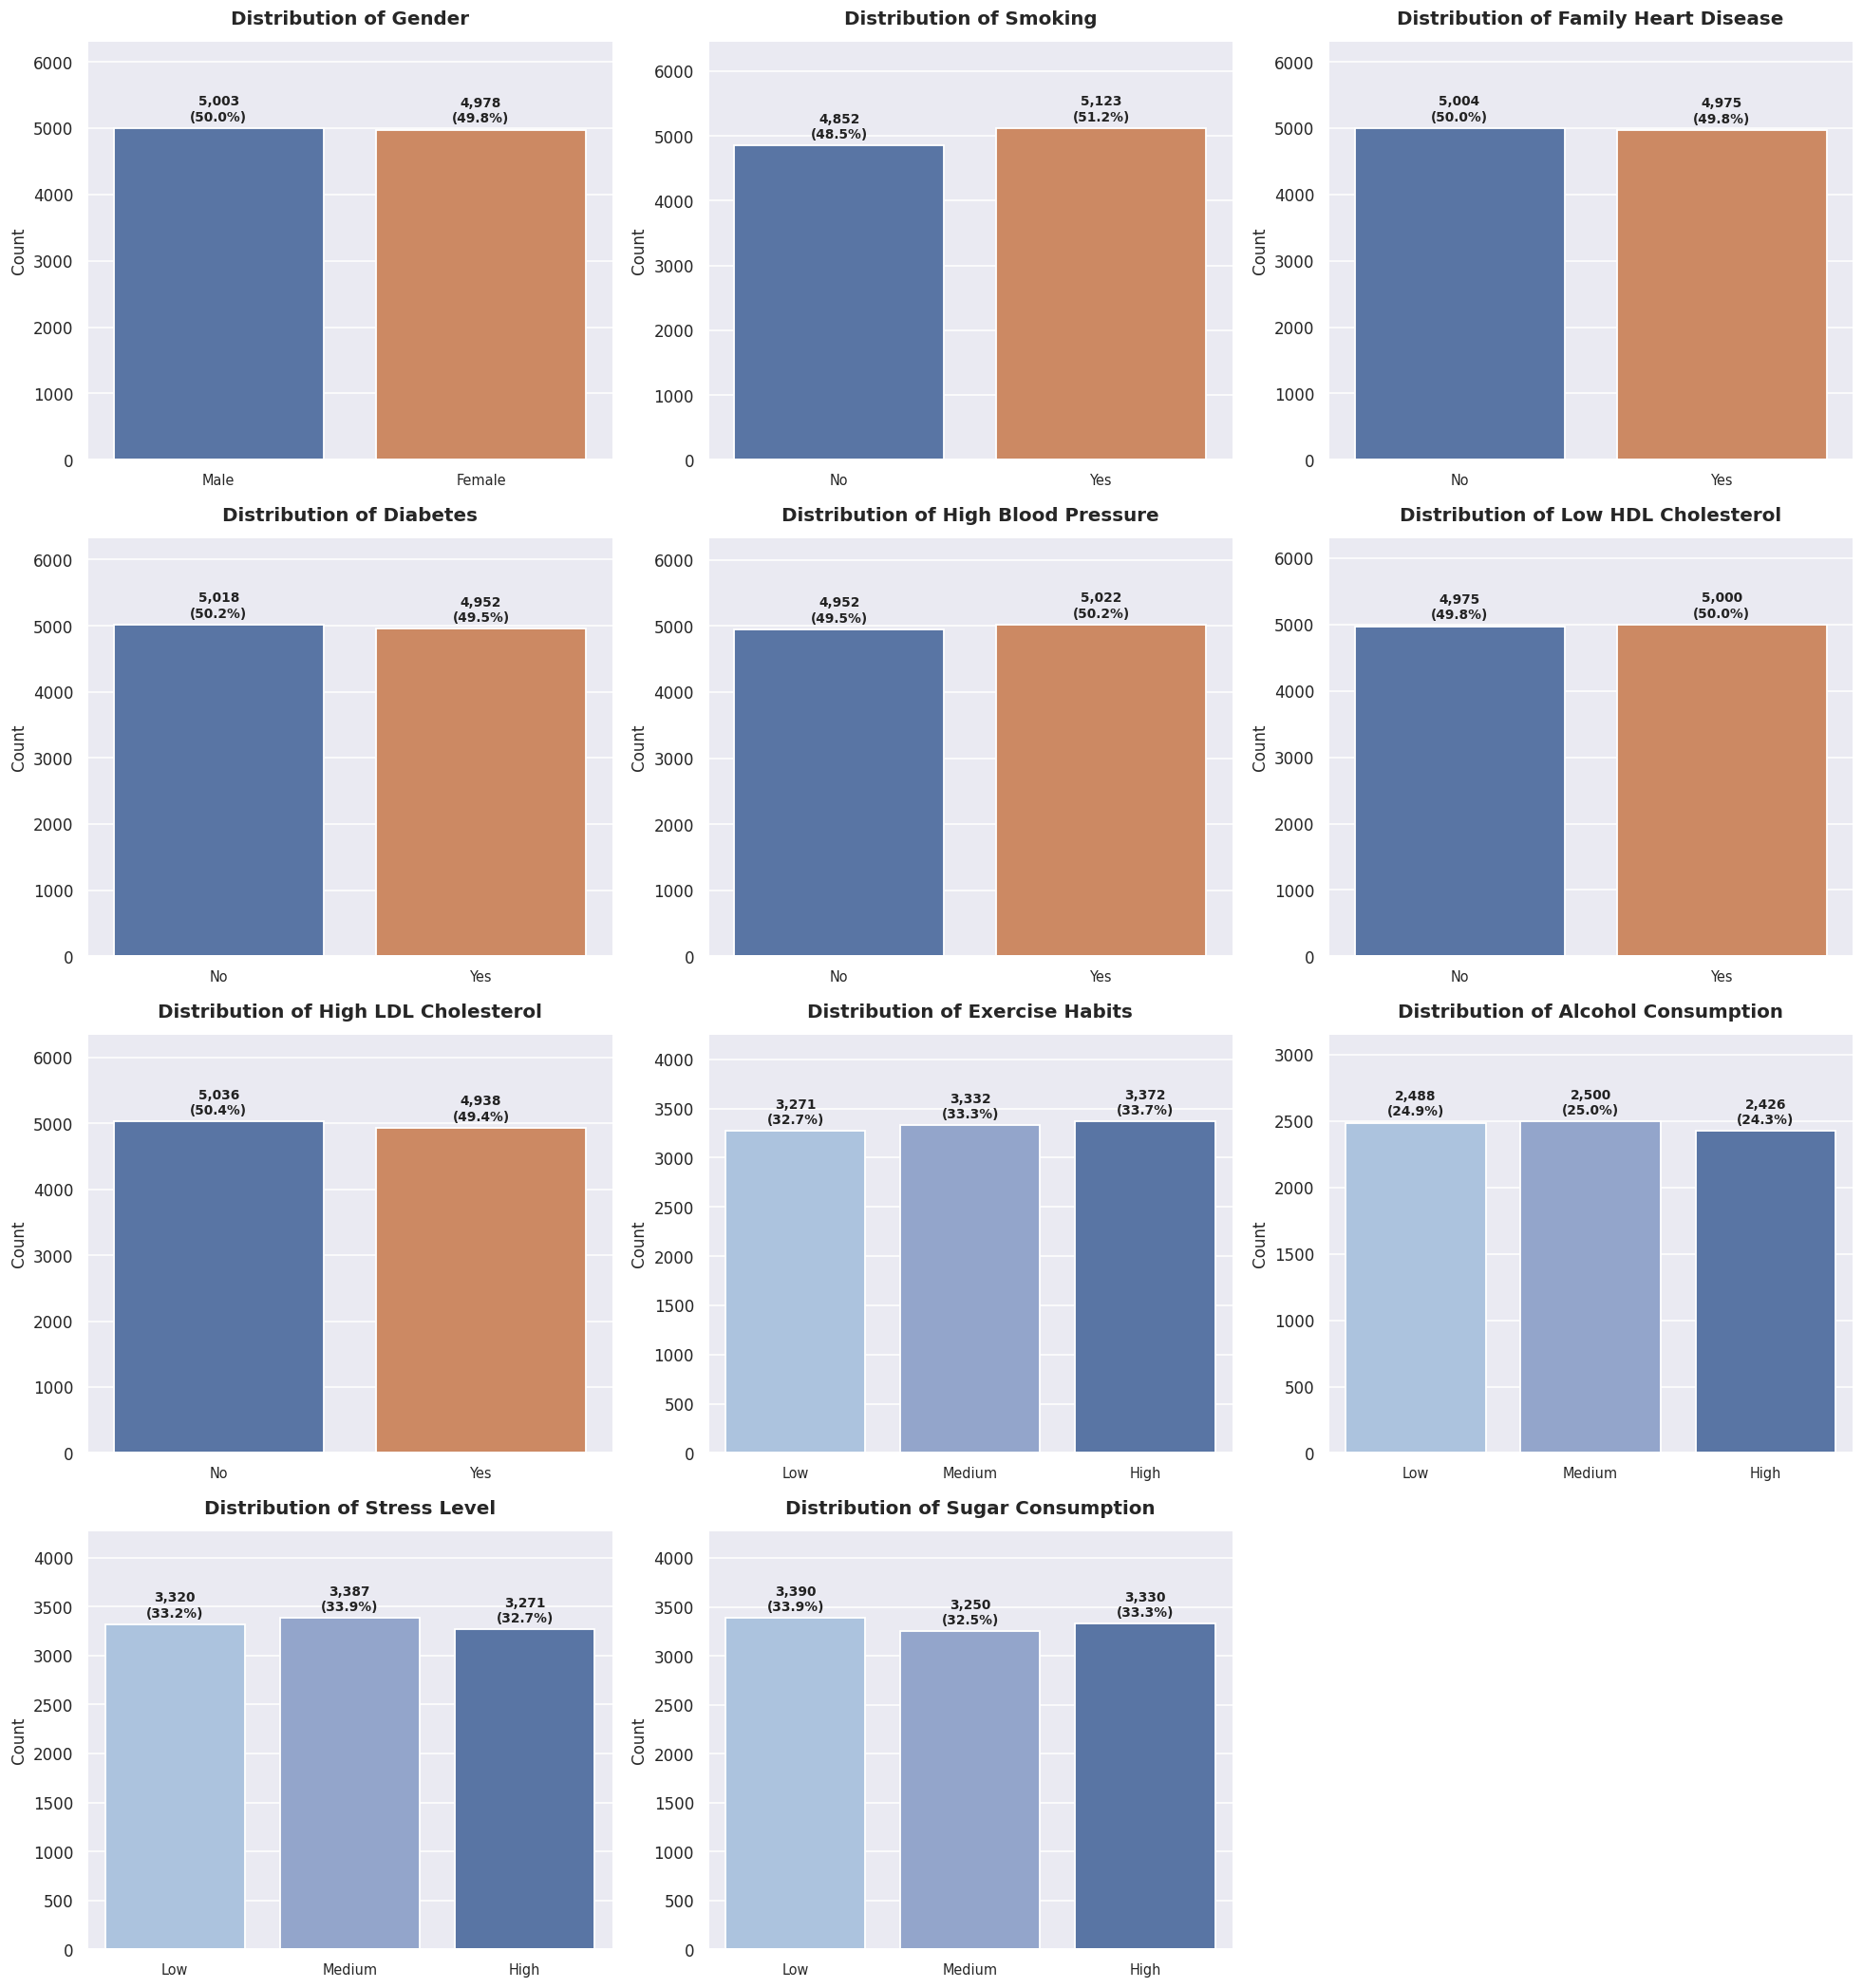

In [ ]:
# ===================== Unified Global Color Map =====================
standard_color_map = {
    # Gender Palette
    "Male": "#4C72B0",
    "Female": "#DD8452",
    # Binary / Standard Target palette
    "No": "#4C72B0",
    "Yes": "#DD8452",
    # Ordinal Scale (Blue Gradient)
    "Low": "#A4C2E6",
    "Medium": "#8AA2D4",
    "High": "#4C72B0",
}

# Predefined left-to-right bar orders
gender_set = {"Male", "Female"}
binary_set = {"Yes", "No"}
ordinal_set = {"Low", "Medium", "High"}

extra_palettes = ["Set2", "viridis", "crest", "Spectral", "Set1"]

# ===================== Custom Feature Ordering =====================
# Filter out the target feature
raw_cat_features = [
    c for c in categorical_features if c != "Heart Disease Status"
]


# Helper function to categorize features for sorting subplots
def get_feature_sort_priority(feature_name):
    # Priority 1: Gender / Sex
    if "gender" in feature_name.lower() or "sex" in feature_name.lower():
        return 1

    cats = set(hd_eda[feature_name].dropna().unique())

    # Priority 2: Binary features (Yes/No)
    if cats.issubset(binary_set):
        return 2

    # Priority 3: Ordinal features (Low/Medium/High)
    if cats.issubset(ordinal_set):
        return 3

    # Priority 4: All other categorical variables
    return 4


# Sort the feature list by defined priority order
cat_features_no_target = sorted(raw_cat_features, key=get_feature_sort_priority)

# ===================== Plot Setup =====================
n_cols = 3
n_rows = int(np.ceil(len(cat_features_no_target) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.8 * n_rows))
axes = axes.flatten()

total_samples = len(hd_eda)

for i, feature in enumerate(cat_features_no_target):
    ax = axes[i]
    existing_categories = hd_eda[feature].dropna().unique()

    # Determine internal bar order
    order = None
    for p_order in [
        ["Male", "Female"],
        ["No", "Yes"],
        ["Low", "Medium", "High"],
    ]:
        if set(existing_categories).issubset(set(p_order)):
            order = [cat for cat in p_order if cat in existing_categories]
            break

    if order is None:
        order = list(hd_eda[feature].value_counts().index)

    # Build color palette map
    feature_palette = {}
    fallback_palette = sns.color_palette(
        extra_palettes[i % len(extra_palettes)], n_colors=len(order)
    )

    for idx, cat in enumerate(order):
        if cat in standard_color_map:
            feature_palette[cat] = standard_color_map[cat]
        else:
            feature_palette[cat] = fallback_palette[idx]

    # Draw countplot
    sns.countplot(
        data=hd_eda,
        x=feature,
        order=order,
        ax=ax,
        hue=feature,
        palette=feature_palette,
        legend=False,
        edgecolor="white",
        linewidth=1.2,
    )

    # Add count and percentage annotations
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            percentage = 100 * height / total_samples
            ax.annotate(
                f"{int(height):,}\n({percentage:.1f}%)",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center",
                va="bottom",
                fontsize=9,
                fontweight="bold",
                color="#222222",
                xytext=(0, 3),
                textcoords="offset points",
            )

    # Smart X-axis label rotation
    n_categories = len(order)
    max_label_len = (
        max([len(str(val)) for val in order]) if n_categories > 0 else 0
    )

    if n_categories > 4 or max_label_len > 8:
        ax.set_xticklabels(
            ax.get_xticklabels(), rotation=30, ha="right", fontsize=9.5
        )
    else:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=9.5)

    # Typography and layout adjustments
    ax.set_title(
        f"Distribution of {feature}", fontsize=13, fontweight="bold", pad=12
    )
    ax.set_xlabel("")
    ax.set_ylabel("Count", fontsize=11)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.20)
    sns.despine(ax=ax)

# Remove unused axes
for j in range(len(cat_features_no_target), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

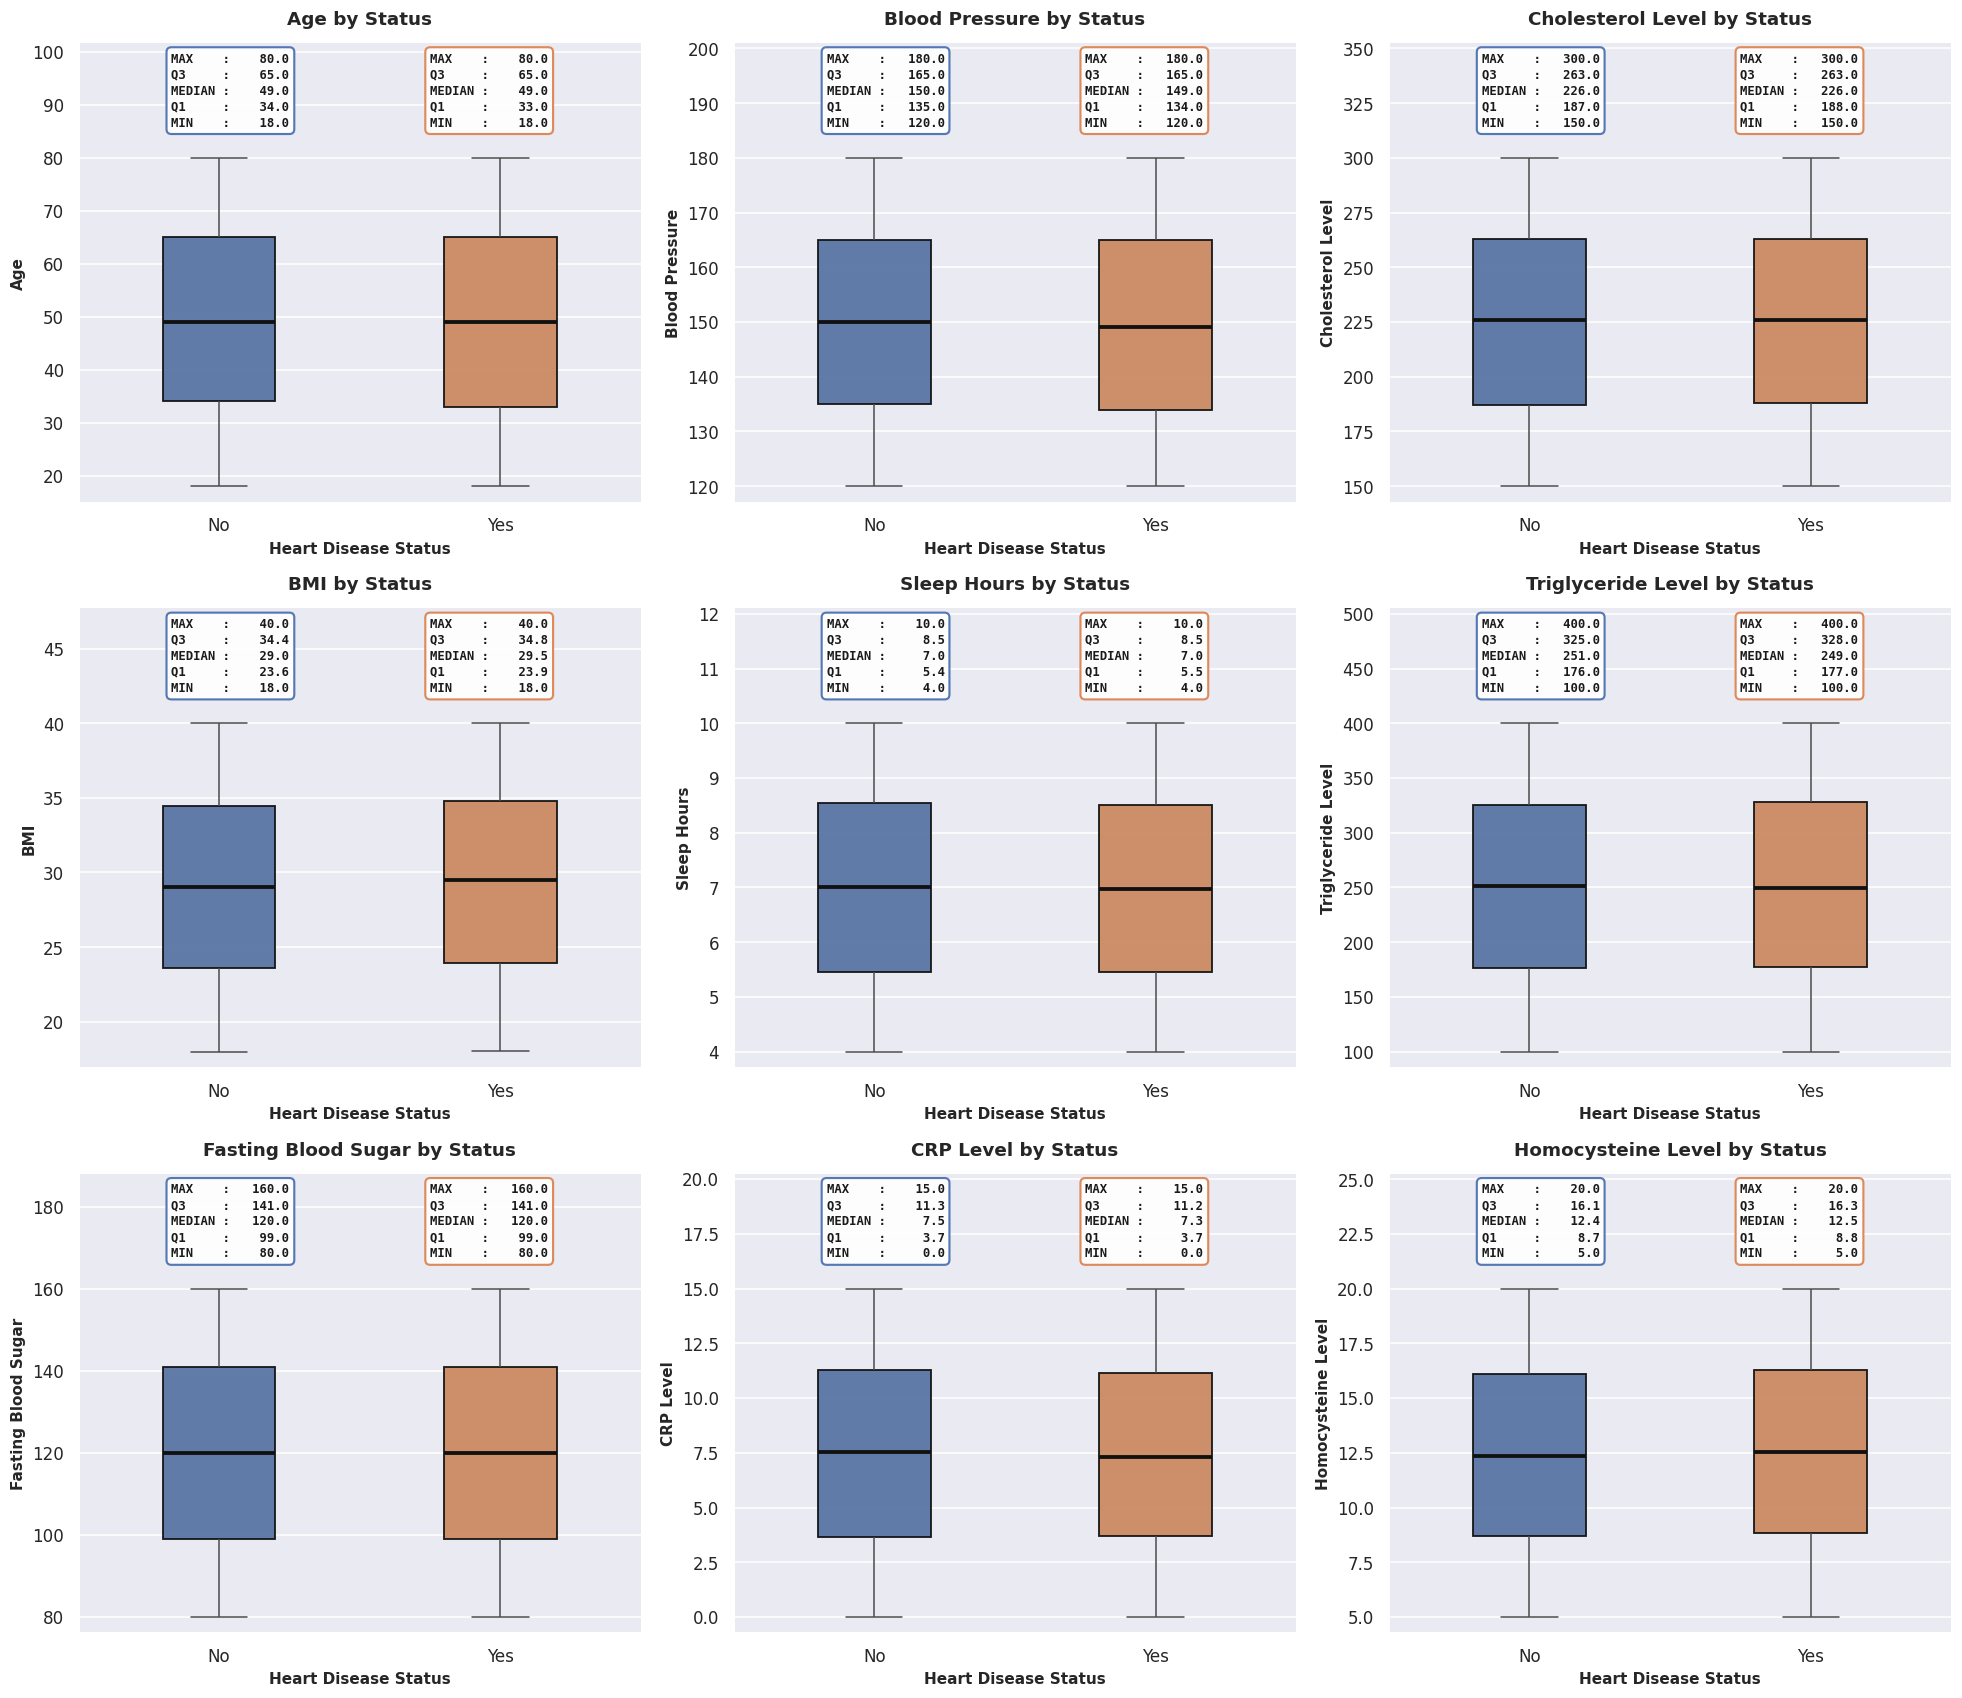

In [ ]:
status_palette = {"No": "#4C72B0", "Yes": "#DD8452"}

# ===================== Boxplots: Numeric Features by Target =====================
n_cols = 3
n_rows = int(np.ceil(len(numeric_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.0 * n_cols, 5.2 * n_rows))
axes = axes.flatten()

for i, feature in enumerate(numeric_features):
    ax = axes[i]
    data = hd_eda.dropna(subset=[feature, "Heart Disease Status"])

    # 1. Boxplot with clean layout parameters
    sns.boxplot(
        data=data,
        x="Heart Disease Status",
        y=feature,
        ax=ax,
        palette=status_palette,
        hue="Heart Disease Status",
        legend=False,
        width=0.4,
        boxprops=dict(alpha=0.95, edgecolor="#111111", linewidth=1.2),
        medianprops=dict(color="#111111", linewidth=2.5),
        showfliers=False,
    )

    # 2. Compute 5-Number Summary Statistics
    stats = (
        data.groupby("Heart Disease Status")[feature]
        .agg(
            min_val="min",
            q1=lambda x: np.percentile(x, 25),
            median="median",
            q3=lambda x: np.percentile(x, 75),
            max_val="max",
        )
    )

    # 3. Tightened Y-limits
    y_min, y_max = data[feature].min(), data[feature].max()
    y_range = y_max - y_min if y_max != y_min else 1.0
    ax.set_ylim(y_min - (y_range * 0.05), y_max + (y_range * 0.35))

    # 4. Stat cards positioned closely above the plot elements
    categories = list(status_palette.keys())
    x_coords = [0.27, 0.73]

    for cat_idx, category in enumerate(categories):
        if category in stats.index:
            row = stats.loc[category]
            cat_color = status_palette[category]

            stat_text = (
                f"MAX    : {row['max_val']:>7.1f}\n"
                f"Q3     : {row['q3']:>7.1f}\n"
                f"MEDIAN : {row['median']:>7.1f}\n"
                f"Q1     : {row['q1']:>7.1f}\n"
                f"MIN    : {row['min_val']:>7.1f}"
            )

            ax.text(
                x_coords[cat_idx],
                0.98,
                stat_text,
                transform=ax.transAxes,
                ha="center",
                va="top",
                fontsize=8.0,
                fontfamily="monospace",
                fontweight="bold",
                color="#1a1a1a",
                linespacing=1.3,
                bbox=dict(
                    boxstyle="round,pad=0.4",
                    facecolor="#ffffff",
                    edgecolor=cat_color,
                    linewidth=1.4,
                    alpha=0.95,
                ),
            )

    # 5. Fine-tuned labels and layout borders
    ax.set_title(
        f"{feature} by Status", fontsize=12, fontweight="bold", pad=12
    )
    ax.set_xlabel("Heart Disease Status", fontsize=10, fontweight="bold")
    ax.set_ylabel(feature, fontsize=10, fontweight="bold")
    sns.despine(ax=ax)

# Remove empty subplots
for j in range(len(numeric_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

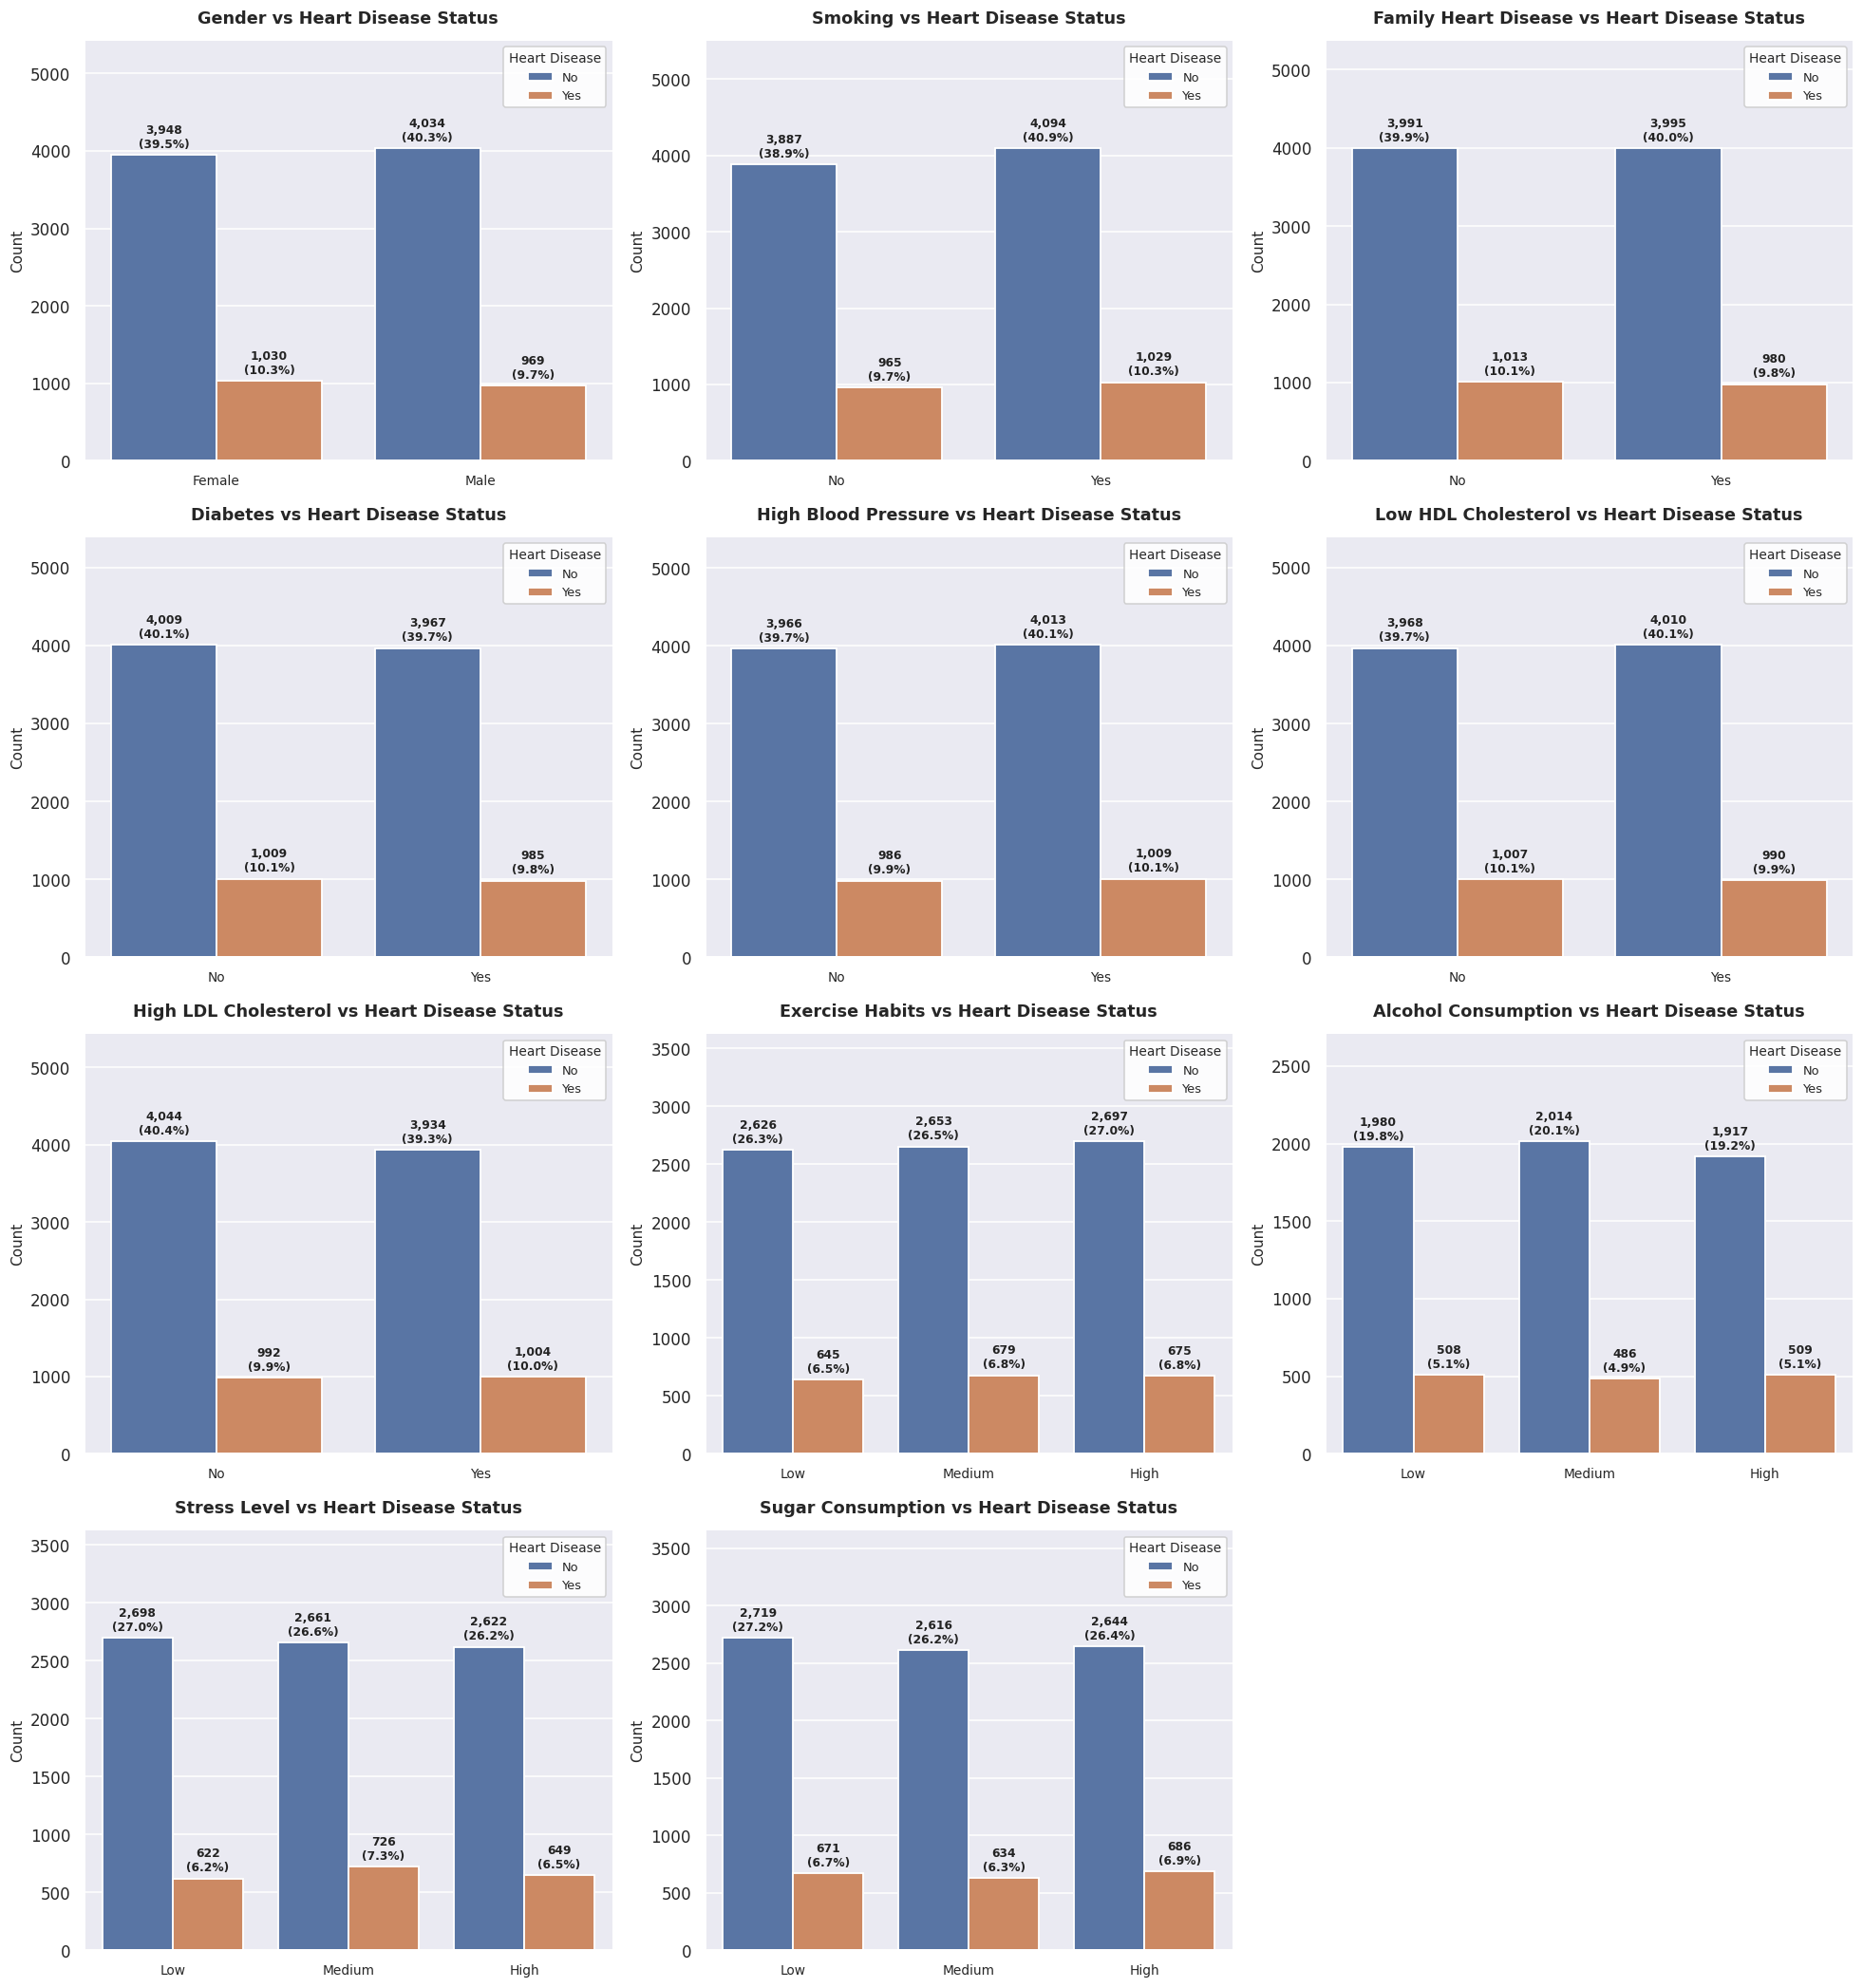

In [ ]:
# Predefined left-to-right bar orders
predefined_orders = [
    ["Female", "Male"],
    ["No", "Yes"],
    ["Low", "Medium", "High"],
]

# ===================== Categorical Features by Heart Disease Status =====================
n_cols = 3
n_rows = int(np.ceil(len(cat_features_no_target) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.8 * n_rows))
axes = axes.flatten()

total_samples = len(hd_eda)

for i, feature in enumerate(cat_features_no_target):
    ax = axes[i]
    existing_categories = hd_eda[feature].dropna().unique()

    # 1. Determine optimal bar order
    order = None
    for p_order in predefined_orders:
        if set(existing_categories).issubset(set(p_order)):
            order = [cat for cat in p_order if cat in existing_categories]
            break

    if order is None:
        order = list(hd_eda[feature].value_counts().index)

    # 2. Draw grouped countplot
    sns.countplot(
        data=hd_eda,
        x=feature,
        hue="Heart Disease Status",
        order=order,
        ax=ax,
        palette=["#4C72B0", "#DD8452"],
        edgecolor="white",
        linewidth=1.2,
    )

    # 3. Add exact count and percentage annotations on top of each bar
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            percentage = 100 * height / total_samples
            ax.annotate(
                f"{int(height):,}\n({percentage:.1f}%)",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center",
                va="bottom",
                fontsize=8,
                fontweight="bold",
                color="#222222",
                xytext=(0, 3),
                textcoords="offset points",
            )

    # 4. Dynamic X-axis label rotation
    n_categories = len(order)
    max_label_len = (
        max([len(str(val)) for val in order]) if n_categories > 0 else 0
    )

    if n_categories > 4 or max_label_len > 8:
        ax.set_xticklabels(
            ax.get_xticklabels(), rotation=30, ha="right", fontsize=9
        )
    else:
        ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=9)

    # 5. Typography and consistent legend positioning
    ax.set_title(
        f"{feature} vs Heart Disease Status", fontsize=11.5, fontweight="bold", pad=12
    )
    ax.set_xlabel("")
    ax.set_ylabel("Count", fontsize=10)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.28)  # Headroom for annotations & upper-right legend

    # Standardized legend location on the right side of every subplot
    ax.legend(
        title="Heart Disease",
        loc="upper right",
        fontsize=8.5,
        title_fontsize=9,
        frameon=True,
        facecolor="white",
        framealpha=0.9,
    )
    sns.despine(ax=ax)

# Remove unused axes
for j in range(len(cat_features_no_target), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

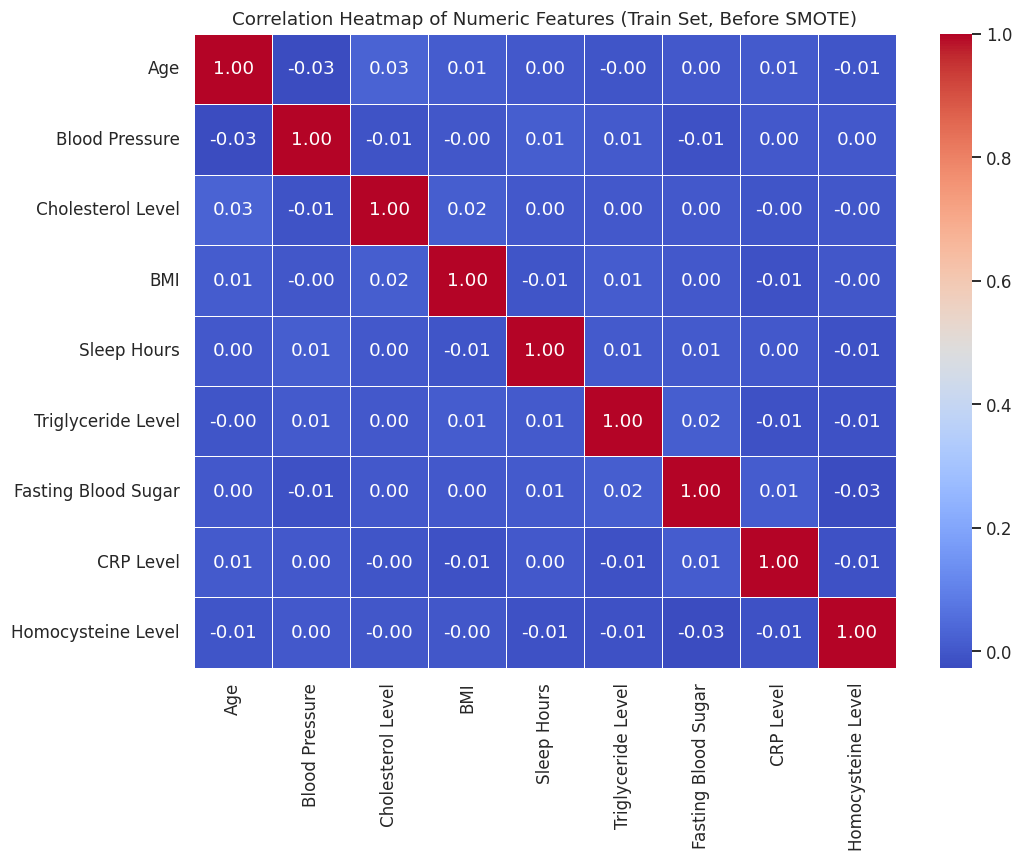

In [ ]:
# ===================== Correlation Heatmap (Numeric Features, train only, before SMOTE) =====================
plt.figure(figsize=(10, 8))
corr_matrix = X_train_enc[numeric_features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features (Train Set, Before SMOTE)')
plt.tight_layout()
plt.show()

<a id='preprocessing'></a>
## Step 5 | Data Preprocessing

### Step 5.1 | Handle Missing Values

In [ ]:
binary_yn = ['Smoking','Family Heart Disease','Diabetes','High Blood Pressure','Low HDL Cholesterol','High LDL Cholesterol']
ordinal_features = ['Exercise Habits','Stress Level','Sugar Consumption']
mode_impute_cols = ['Gender'] + binary_yn + ordinal_features

# NUMERIC FEATURES (Median imputation)
median_imputer = SimpleImputer(strategy='median')
hd[numeric_features] = median_imputer.fit_transform(hd[numeric_features])

# BINARY, GENDER, ORDINAL FEATURES (Most-frequent imputation)
mode_imputer = SimpleImputer(strategy='most_frequent')
hd[mode_impute_cols] = mode_imputer.fit_transform(hd[mode_impute_cols])

# ALCOHOL CONSUMPTION (Constant imputation)
constant_imputer = SimpleImputer(strategy='constant', fill_value='None')
hd[['Alcohol Consumption']] = constant_imputer.fit_transform(hd[['Alcohol Consumption']])

# CHECK REMAINING MISSING VALUES
print('Remaining missing values — whole dataset:', hd.isnull().sum().sum())

Remaining missing values — whole dataset: 0


### Step 5.2 | Encode Categorical Features

In [ ]:
# ============ Encode the Target ============
hd['Heart Disease Status'] = hd['Heart Disease Status'].map({'Yes': 1, 'No': 0})

# ============ One-Hot Encode Categorical Features ============
categorical_to_encode = ['Gender'] + binary_yn + ['Alcohol Consumption'] + ordinal_features

ohe = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False, dtype=int)
ohe.fit(hd[categorical_to_encode])

hd_ohe = pd.DataFrame(
    ohe.transform(hd[categorical_to_encode]),
    columns=ohe.get_feature_names_out(categorical_to_encode),
    index=hd.index
)

hd_enc = pd.concat([hd.drop(columns=categorical_to_encode), hd_ohe], axis=1)
display(hd_enc.head())

,Age,Blood Pressure,Cholesterol Level,BMI,Sleep Hours,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status,...,High LDL Cholesterol_Yes,Alcohol Consumption_Low,Alcohol Consumption_Medium,Alcohol Consumption_None,Exercise Habits_Low,Exercise Habits_Medium,Stress Level_Low,Stress Level_Medium,Sugar Consumption_Low,Sugar Consumption_Medium
0,56.0,153.0,155.0,24.991591,7.633228,342.0,120.0,12.969246,12.387250,0,...,0,0,0,0,0,0,0,1,0,1
1,69.0,146.0,286.0,25.221799,8.744034,133.0,157.0,9.355389,19.298875,0,...,0,0,1,0,0,0,0,0,0,1
2,46.0,126.0,216.0,29.855447,4.440440,393.0,92.0,12.709873,11.230926,0,...,1,1,0,0,1,0,1,0,1,0
3,32.0,122.0,293.0,24.130477,5.249405,293.0,94.0,12.509046,5.961958,0,...,1,1,0,0,0,0,0,0,0,0
4,60.0,166.0,242.0,20.486289,7.030971,263.0,154.0,10.381259,8.153887,0,...,0,1,0,0,1,0,0,0,0,0


### Step 5.3 | Train/Test Split

In [ ]:
# ============ Separate Features and Target ============
X = hd_enc.drop(columns=['Heart Disease Status'])
y = hd_enc['Heart Disease Status']

# ============ Train/Test Split ============
X_train_enc, X_test_enc, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=400, stratify=y
)

print('Train shape:', X_train_enc.shape, ' Test shape:', X_test_enc.shape)
print('Train class balance:\n', y_train.value_counts(normalize=True).round(3))

Train shape: (7000, 25)  Test shape: (3000, 25)
Train class balance:
 Heart Disease Status
0    0.8
1    0.2
Name: proportion, dtype: float64


### Step 5.4 | Feature Relationships (Train Set, Before SMOTE)

Stress Level_Low             -0.020703
Gender_Male                  -0.016286
Blood Pressure               -0.016154
Sugar Consumption_Medium     -0.013598
Sugar Consumption_Low        -0.009052
Exercise Habits_Low          -0.008383
Diabetes_Yes                 -0.007000
Alcohol Consumption_Low      -0.005854
Alcohol Consumption_None     -0.005361
Sleep Hours                  -0.005218
Cholesterol Level            -0.000875
Family Heart Disease_Yes     -0.000714
Age                           0.000028
Alcohol Consumption_Medium    0.003610
CRP Level                     0.005013
Triglyceride Level            0.005272
Fasting Blood Sugar           0.005380
Smoking_Yes                   0.006858
Homocysteine Level            0.007894
High Blood Pressure_Yes       0.008715
Exercise Habits_Medium        0.011515
Low HDL Cholesterol_Yes       0.011571
High LDL Cholesterol_Yes      0.014286
BMI                           0.015947
Stress Level_Medium           0.031187
Name: Heart Disease Statu

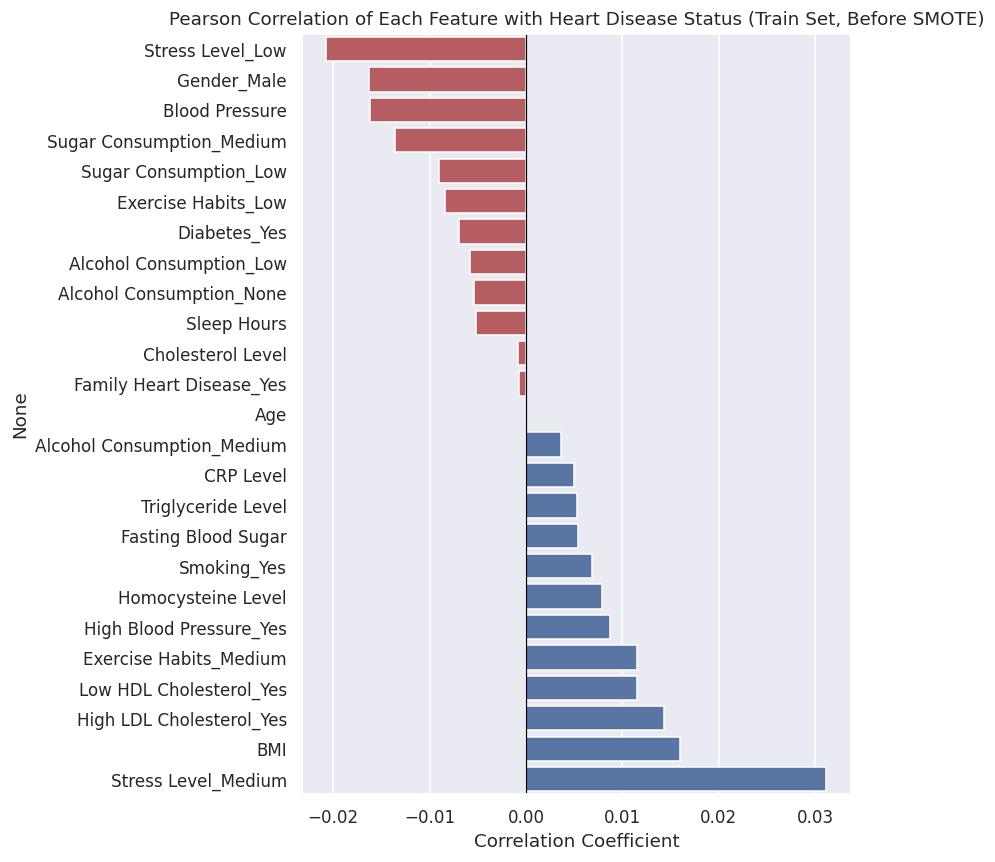

In [ ]:
# ===================== Correlation of Encoded Features with Target (Pearson, train only, before SMOTE) =====================
train_with_target = X_train_enc.copy()
train_with_target['Heart Disease Status'] = y_train

target_corr = train_with_target.corr(numeric_only=True)['Heart Disease Status'].drop('Heart Disease Status')
target_corr = target_corr.sort_values()

print(target_corr)

plt.figure(figsize=(8, 8))
sns.barplot(x=target_corr.values, y=target_corr.index,
            palette=['#C44E52' if v < 0 else '#4C72B0' for v in target_corr.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Pearson Correlation of Each Feature with Heart Disease Status (Train Set, Before SMOTE)')
plt.xlabel('Correlation Coefficient')
plt.tight_layout()
plt.show()

                       Feature  Chi2 Statistic  p-value
0          Stress Level_Medium           6.645   0.0099
1             Stress Level_Low           2.891   0.0891
2                  Gender_Male           1.776   0.1826
3     High LDL Cholesterol_Yes           1.358   0.2439
4     Sugar Consumption_Medium           1.223   0.2689
5      Low HDL Cholesterol_Yes           0.880   0.3481
6       Exercise Habits_Medium           0.868   0.3515
7        Sugar Consumption_Low           0.527   0.4680
8      High Blood Pressure_Yes           0.489   0.4844
9          Exercise Habits_Low           0.448   0.5032
10                Diabetes_Yes           0.309   0.5783
11                 Smoking_Yes           0.296   0.5865
12     Alcohol Consumption_Low           0.207   0.6493
13    Alcohol Consumption_None           0.172   0.6784
14  Alcohol Consumption_Medium           0.072   0.7889
15    Family Heart Disease_Yes           0.001   0.9762


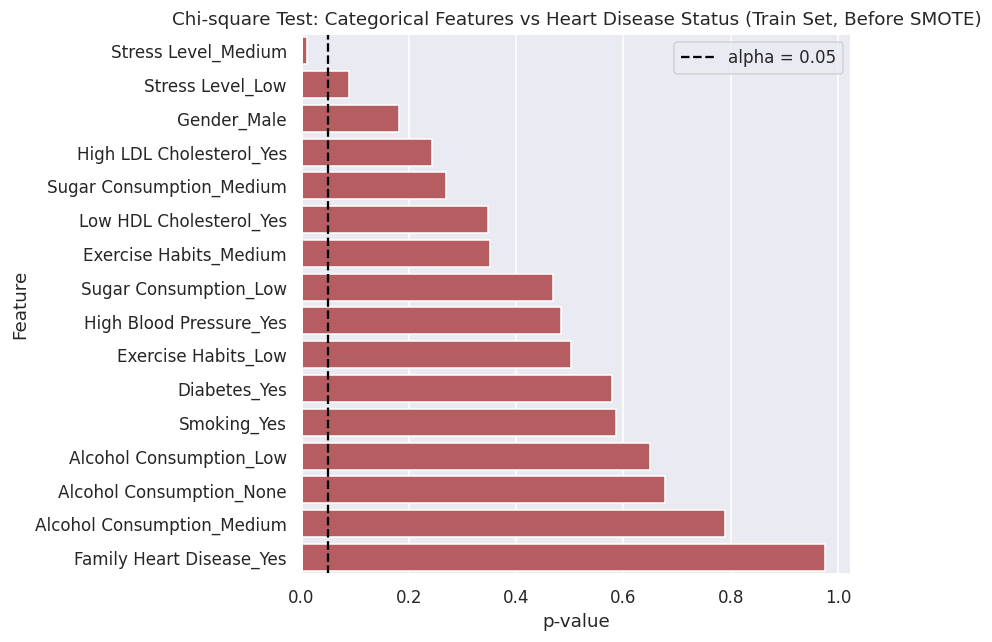

In [ ]:
# ===================== Chi-square Test: Categorical Features vs Target (train only, before SMOTE) =====================
from scipy import stats

current_categorical_cols = [c for c in X_train_enc.columns if c not in numeric_features]

chi_square_results = []
for col in current_categorical_cols:
    contingency = pd.crosstab(X_train_enc[col], y_train)
    chi2, p, dof, expected = stats.chi2_contingency(contingency)
    chi_square_results.append({'Feature': col, 'Chi2 Statistic': round(chi2, 3), 'p-value': round(p, 4)})

chi_square_df = pd.DataFrame(chi_square_results).sort_values(by='p-value').reset_index(drop=True)
print(chi_square_df)

plt.figure(figsize=(8, 6))
sns.barplot(data=chi_square_df, x='p-value', y='Feature', color='#C44E52')
plt.axvline(0.05, color='black', linestyle='--', label='alpha = 0.05')
plt.title('Chi-square Test: Categorical Features vs Heart Disease Status (Train Set, Before SMOTE)')
plt.legend()
plt.tight_layout()
plt.show()

                            Mutual Information
High Blood Pressure_Yes                 0.0165
Gender_Male                             0.0084
Cholesterol Level                       0.0039
Stress Level_Low                        0.0039
Age                                     0.0027
Sugar Consumption_Low                   0.0018
Alcohol Consumption_Low                 0.0017
Sugar Consumption_Medium                0.0017
Alcohol Consumption_Medium              0.0009
Triglyceride Level                      0.0007
CRP Level                               0.0000
Homocysteine Level                      0.0000
Sleep Hours                             0.0000
Blood Pressure                          0.0000
BMI                                     0.0000
Fasting Blood Sugar                     0.0000
Smoking_Yes                             0.0000
High LDL Cholesterol_Yes                0.0000
Low HDL Cholesterol_Yes                 0.0000
Family Heart Disease_Yes                0.0000
Diabetes_Yes 

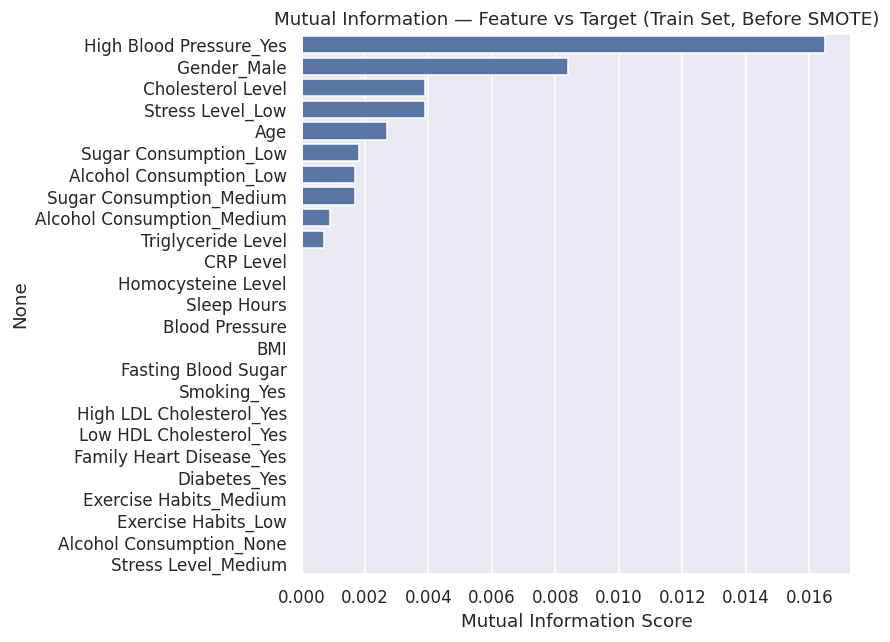

In [ ]:
# ===================== Mutual Information: Feature vs Target (train only, before SMOTE) =====================
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(X_train_enc, y_train, random_state=400)
mi_table = pd.Series(mi_scores, index=X_train_enc.columns).sort_values(ascending=False)
mi_table = mi_table.round(4).to_frame(name='Mutual Information')
print(mi_table)

plt.figure(figsize=(8, 6))
sns.barplot(x=mi_table['Mutual Information'], y=mi_table.index, color='#4C72B0')
plt.title('Mutual Information — Feature vs Target (Train Set, Before SMOTE)')
plt.xlabel('Mutual Information Score')
plt.tight_layout()
plt.show()

### Step 5.5 | SMOTE + Tomek Links

Before resampling (y_train):     {0: 5600, 1: 1400}
After  resampling (y_train_res): {0: 5557, 1: 5557}


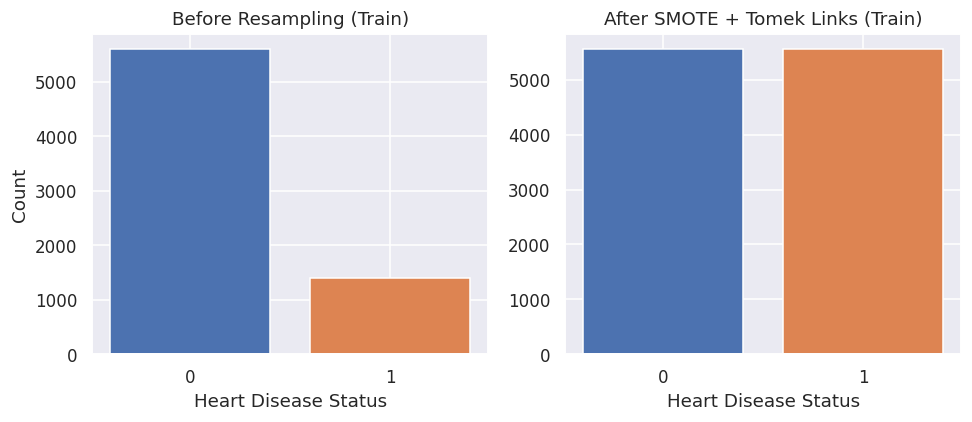

In [ ]:
# ============ SMOTE + Tomek Links (train only) ============
smote_tomek = SMOTETomek(
    smote=SMOTE(sampling_strategy='minority', random_state=400),
    random_state=400
)
X_train_res, y_train_res = smote_tomek.fit_resample(X_train_enc, y_train)

print('Before resampling (y_train):    ', y_train.value_counts().to_dict())
print('After  resampling (y_train_res):', y_train_res.value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
before = y_train.value_counts().sort_index()
after = y_train_res.value_counts().sort_index()

axes[0].bar(before.index.astype(str), before.values, color=['#4C72B0', '#DD8452'])
axes[0].set_title('Before Resampling (Train)')
axes[0].set_xlabel('Heart Disease Status')
axes[0].set_ylabel('Count')

axes[1].bar(after.index.astype(str), after.values, color=['#4C72B0', '#DD8452'])
axes[1].set_title('After SMOTE + Tomek Links (Train)')
axes[1].set_xlabel('Heart Disease Status')

plt.tight_layout()
plt.show()

### Step 5.6 | Scaling

In [ ]:
standard_scaler = StandardScaler()

X_train_final = X_train_res.copy()
X_test_final = X_test_enc.copy()

X_train_final[numeric_features] = standard_scaler.fit_transform(X_train_res[numeric_features])
X_test_final[numeric_features] = standard_scaler.transform(X_test_enc[numeric_features])

print('Standardized numeric feature stats — train (mean ~ 0, std ~ 1):')
X_train_final[numeric_features].agg(['mean', 'std']).T.round(3)

Standardized numeric feature stats — train (mean ~ 0, std ~ 1):


,mean,std
Age,-0.0,1.0
Blood Pressure,0.0,1.0
Cholesterol Level,-0.0,1.0
BMI,-0.0,1.0
Sleep Hours,-0.0,1.0
Triglyceride Level,-0.0,1.0
Fasting Blood Sugar,0.0,1.0
CRP Level,0.0,1.0
Homocysteine Level,-0.0,1.0


In [ ]:
# ============ Hyperparameter Tuning Function ============
def tune_clf_hyperparameters(pipeline, param_grid, X_train, y_train, scoring='f1', n_splits=10):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=False)
    grid_search = GridSearchCV(pipeline, param_grid, scoring=scoring, cv=cv, n_jobs=-1)
    grid_search.fit(X_train, y_train)
    return grid_search.best_estimator_, grid_search.best_params_

# ============ Randomized Hyperparameter Tuning Function ============
def tune_clf_random_search(pipeline, param_distributions, X_train, y_train,
                            scoring='f1', n_splits=10, n_iter=50):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=False)
    random_search = RandomizedSearchCV(
        pipeline, param_distributions, n_iter=n_iter, scoring=scoring,
        cv=cv, n_jobs=-1, random_state=400
    )
    random_search.fit(X_train, y_train)
    return random_search.best_estimator_, random_search.best_params_

# ============ Model Performance Evaluation Function ============
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)

    # Confusion matrix cells (class 1 = positive)
    cm = confusion_matrix(y_test, y_pred)
    c_00, c_01 = cm[0, 0], cm[0, 1]   # True Negatives, False Positives
    c_10, c_11 = cm[1, 0], cm[1, 1]   # False Negatives, True Positives

    # Accuracy: correct predictions / total
    accuracy = (c_00 + c_11) / (c_00 + c_11 + c_01 + c_10)

    # Precision: of predicted positives, how many were correct
    precision = c_11 / (c_11 + c_01)

    # Recall: of actual positives, how many were caught
    recall = c_11 / (c_11 + c_10)

    # F1-score: harmonic mean of precision and recall
    f1 = 2 * (precision * recall) / (precision + recall)

    metrics = {
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'accuracy': accuracy,
        'balanced_accuracy': balanced_accuracy_score(y_test, y_pred),
        'mcc': matthews_corrcoef(y_test, y_pred),
    }
    if hasattr(model, 'predict_proba'):
        y_proba = model.predict_proba(X_test)[:, 1]
        metrics['roc_auc'] = roc_auc_score(y_test, y_proba)
        metrics['pr_auc'] = average_precision_score(y_test, y_proba)
    return pd.DataFrame(metrics, index=[model_name])

# ============ Confusion Matrix Visualization Function ============
def plot_confusion(model, X_test, y_test, model_name):
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'{model_name} — Confusion Matrix')
    plt.show()

# ============ Permutation Importance Plot Function ============
def plot_permutation_importance(model, X_test, y_test, model_name, color, n_repeats=10, top_n=10):
    result = permutation_importance(
        model, X_test, y_test, n_repeats=n_repeats, random_state=400, scoring='roc_auc', n_jobs=-1
    )
    importances = pd.Series(result.importances_mean, index=X_test.columns).sort_values(ascending=False)

    plt.figure(figsize=(8, 6))
    sns.barplot(x=importances.values[:top_n], y=importances.index[:top_n], color=color)
    plt.title(f'{model_name} — Top {top_n} Permutation Importances (Test Set, scoring=roc_auc)')
    plt.xlabel('Mean decrease in ROC-AUC')
    plt.tight_layout()
    plt.show()
    return importances

<a id='nb'></a>
## Step 6 | Gaussian Naive Bayes — Baseline Model

In [ ]:
nb_pipeline = Pipeline([
    ('nb', GaussianNB())
])

In [ ]:
nb_param_grid = {
    'nb__var_smoothing': np.logspace(0, -9, num=100)
}

n_combos = 1
for values in nb_param_grid.values():
    n_combos *= len(values)
print(f'GridSearchCV will exhaustively try {n_combos} combinations x 10 CV folds = {n_combos * 10} fits')

best_nb, best_nb_params = tune_clf_hyperparameters(
    nb_pipeline, nb_param_grid, X_train_final, y_train_res, scoring='f1', n_splits=10
)
print('GaussianNB Optimal Hyperparameters:\n', best_nb_params)

GridSearchCV will exhaustively try 100 combinations x 10 CV folds = 1000 fits
GaussianNB Optimal Hyperparameters:
 {'nb__var_smoothing': np.float64(0.1)}


In [ ]:
print('Train performance:')
print(classification_report(y_train_res, best_nb.predict(X_train_final)))
print('Test performance:')
print(classification_report(y_test, best_nb.predict(X_test_final)))

Train performance:
              precision    recall  f1-score   support

           0       0.80      0.68      0.73      5557
           1       0.72      0.83      0.77      5557

    accuracy                           0.75     11114
   macro avg       0.76      0.75      0.75     11114
weighted avg       0.76      0.75      0.75     11114

Test performance:
              precision    recall  f1-score   support

           0       0.81      0.71      0.76      2400
           1       0.23      0.34      0.27       600

    accuracy                           0.64      3000
   macro avg       0.52      0.53      0.52      3000
weighted avg       0.69      0.64      0.66      3000



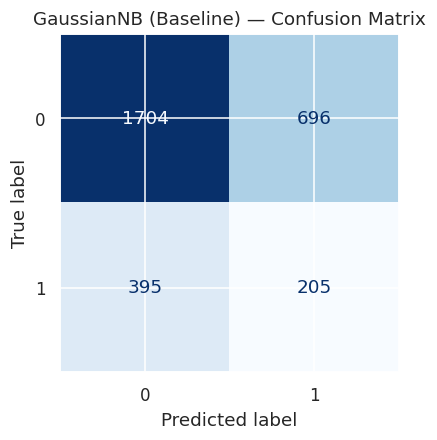

,precision,recall,f1,accuracy,balanced_accuracy,mcc,roc_auc,pr_auc
GaussianNB (Baseline),0.227525,0.341667,0.273151,0.636333,0.525833,0.045084,0.529398,0.218154


In [ ]:
nb_evaluation = evaluate_model(best_nb, X_test_final, y_test, 'GaussianNB (Baseline)')
plot_confusion(best_nb, X_test_final, y_test, 'GaussianNB (Baseline)')
nb_evaluation

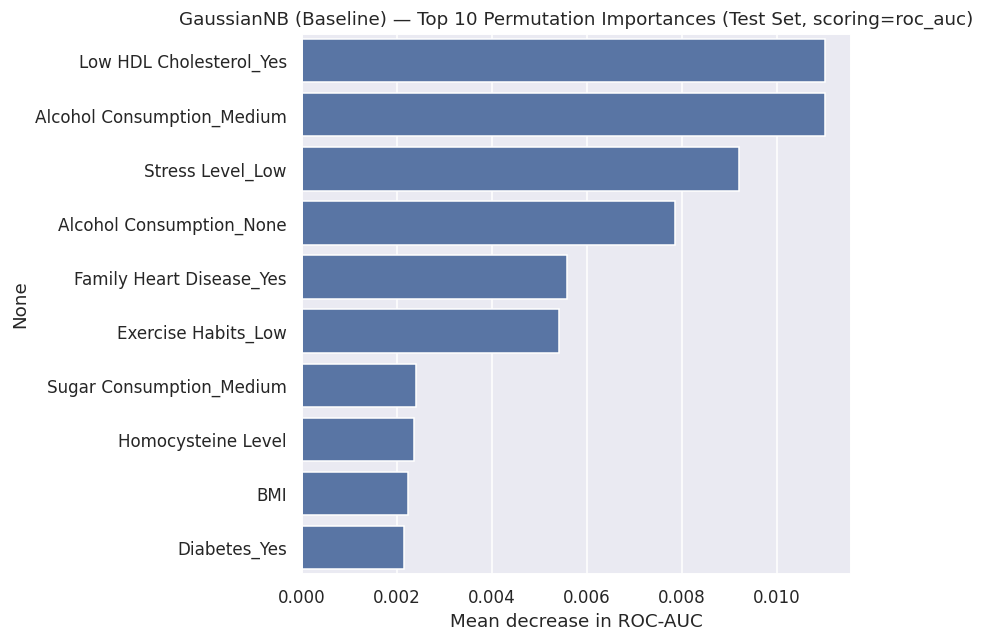

In [ ]:
# ============ Permutation Feature Importance (Test Set) ============
importances_nb = plot_permutation_importance(best_nb, X_test_final, y_test, 'GaussianNB (Baseline)', color='#4C72B0')

<a id='rf'></a>
## Step 7 | Random Forest Model

In [ ]:
rf_pipeline = Pipeline([
    ('clf', RandomForestClassifier(random_state=400))
])

In [ ]:
rf_param_grid = {
    'clf__n_estimators': [50, 100, 150],
    'clf__max_depth': [6, 8, 10, None],
    'clf__min_samples_split': [2, 5],
    'clf__min_samples_leaf': [1, 2]
}

n_combos = 1
for values in rf_param_grid.values():
    n_combos *= len(values)
print(f'GridSearchCV will exhaustively try {n_combos} combinations x 10 CV folds = {n_combos * 10} fits')

best_rf, best_rf_params = tune_clf_hyperparameters(
    rf_pipeline, rf_param_grid, X_train_final, y_train_res, scoring='f1', n_splits=10
)
print('RF Optimal Hyperparameters:\n', best_rf_params)

GridSearchCV will exhaustively try 48 combinations x 10 CV folds = 480 fits
RF Optimal Hyperparameters:
 {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2, 'clf__n_estimators': 150}


In [ ]:
print('Train performance:')
print(classification_report(y_train_res, best_rf.predict(X_train_final)))
print('Test performance:')
print(classification_report(y_test, best_rf.predict(X_test_final)))

Train performance:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5557
           1       1.00      1.00      1.00      5557

    accuracy                           1.00     11114
   macro avg       1.00      1.00      1.00     11114
weighted avg       1.00      1.00      1.00     11114

Test performance:
              precision    recall  f1-score   support

           0       0.80      0.93      0.86      2400
           1       0.23      0.08      0.12       600

    accuracy                           0.76      3000
   macro avg       0.52      0.51      0.49      3000
weighted avg       0.69      0.76      0.71      3000



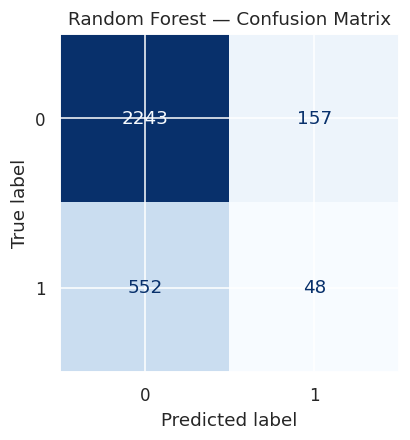

,precision,recall,f1,accuracy,balanced_accuracy,mcc,roc_auc,pr_auc
Random Forest,0.234146,0.08,0.119255,0.763667,0.507292,0.023119,0.52165,0.217437


In [ ]:
rf_evaluation = evaluate_model(best_rf, X_test_final, y_test, 'Random Forest')
plot_confusion(best_rf, X_test_final, y_test, 'Random Forest')
rf_evaluation

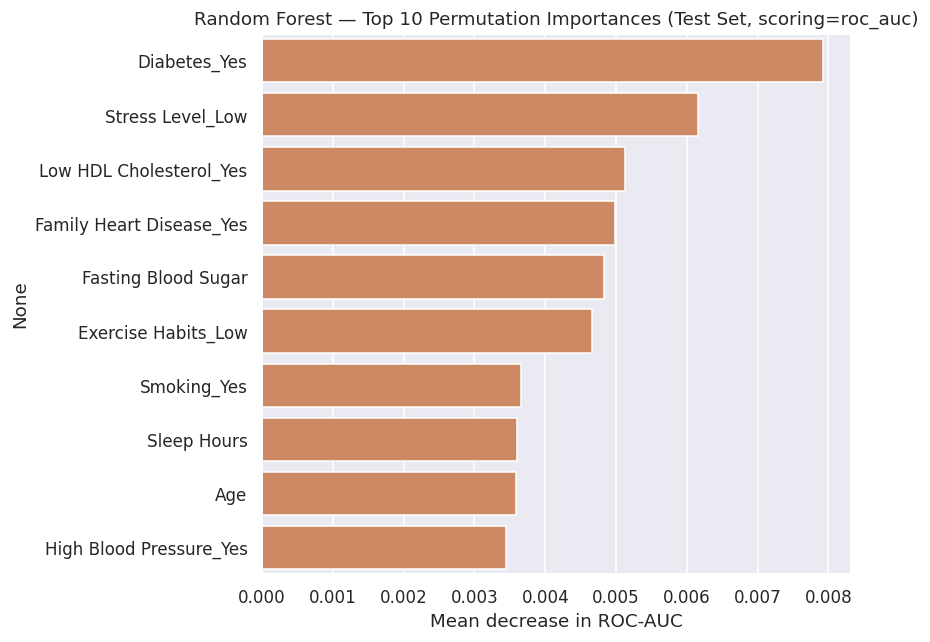

In [ ]:
# ============ Permutation Feature Importance (Test Set) ============
importances_rf = plot_permutation_importance(best_rf, X_test_final, y_test, 'Random Forest', color='#DD8452')

<a id='xgb'></a>
## Step 8 | XGBoost Model

In [ ]:
xgb_pipeline = Pipeline([
    ('clf', XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=400,
        n_jobs=-1
    ))
])

In [ ]:
xgb_param_dist = {
    'clf__n_estimators': randint(50, 200),
    'clf__max_depth': randint(3, 9),
    'clf__learning_rate': uniform(0.01, 0.19),
    'clf__subsample': uniform(0.7, 0.3),
    'clf__colsample_bytree': uniform(0.7, 0.3),
    'clf__min_child_weight': randint(1, 6),
    'clf__reg_lambda': uniform(1, 9),
    'clf__reg_alpha': uniform(0, 1)
}

N_ITER = 50
print(f'RandomizedSearchCV will try {N_ITER} sampled combinations x 10 CV folds = {N_ITER * 10} fits')

best_xgb, best_xgb_params = tune_clf_random_search(
    xgb_pipeline, xgb_param_dist, X_train_final, y_train_res,
    scoring='f1', n_splits=10, n_iter=N_ITER
)
print('XGBoost Optimal Hyperparameters:')
for param, value in best_xgb_params.items():
    print(f'{param}: {value}')

RandomizedSearchCV will try 50 sampled combinations x 10 CV folds = 500 fits
XGBoost Optimal Hyperparameters:
clf__colsample_bytree: 0.977901239893957
clf__learning_rate: 0.12478914594281908
clf__max_depth: 8
clf__min_child_weight: 5
clf__n_estimators: 197
clf__reg_alpha: 0.3242057529276181
clf__reg_lambda: 9.358432431010668
clf__subsample: 0.8394173972879175


In [ ]:
print('Train performance:')
print(classification_report(y_train_res, best_xgb.predict(X_train_final)))
print('Test performance:')
print(classification_report(y_test, best_xgb.predict(X_test_final)))

Train performance:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      5557
           1       0.99      0.96      0.98      5557

    accuracy                           0.98     11114
   macro avg       0.98      0.98      0.98     11114
weighted avg       0.98      0.98      0.98     11114

Test performance:
              precision    recall  f1-score   support

           0       0.80      0.91      0.85      2400
           1       0.21      0.10      0.14       600

    accuracy                           0.75      3000
   macro avg       0.51      0.50      0.49      3000
weighted avg       0.68      0.75      0.71      3000



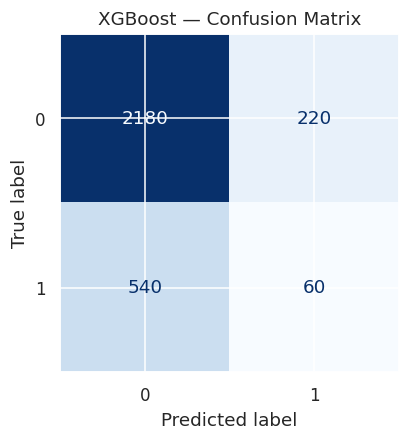

,precision,recall,f1,accuracy,balanced_accuracy,mcc,roc_auc,pr_auc
XGBoost,0.214286,0.1,0.136364,0.746667,0.504167,0.011459,0.519769,0.218386


In [ ]:
xgb_evaluation = evaluate_model(best_xgb, X_test_final, y_test, 'XGBoost')
plot_confusion(best_xgb, X_test_final, y_test, 'XGBoost')
xgb_evaluation

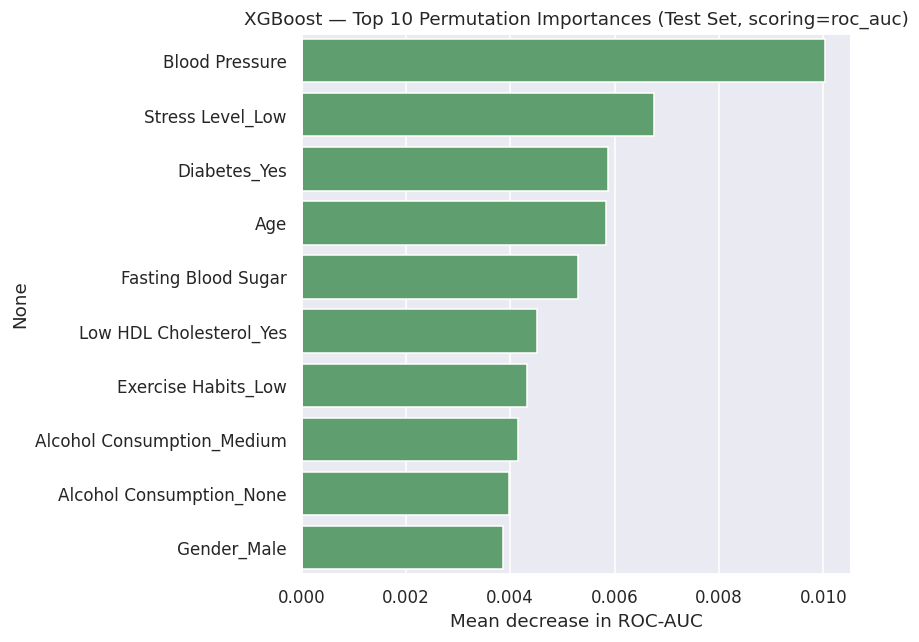

In [ ]:
# ============ Permutation Feature Importance (Test Set) ============
importances_xgb = plot_permutation_importance(best_xgb, X_test_final, y_test, 'XGBoost', color='#55A868')

<a id='compare'></a>
## Step 9 | Model Comparison

                       precision  recall     f1  accuracy  balanced_accuracy    mcc  roc_auc  pr_auc
Random Forest              0.234   0.080  0.119     0.764              0.507  0.023    0.522   0.217
XGBoost                    0.214   0.100  0.136     0.747              0.504  0.011    0.520   0.218
GaussianNB (Baseline)      0.228   0.342  0.273     0.636              0.526  0.045    0.529   0.218


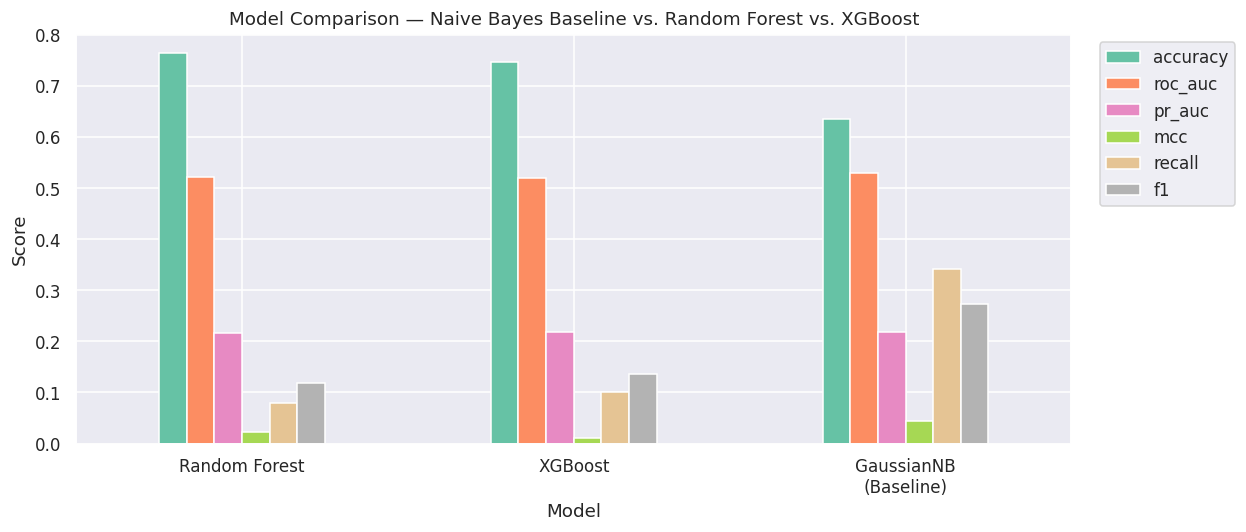

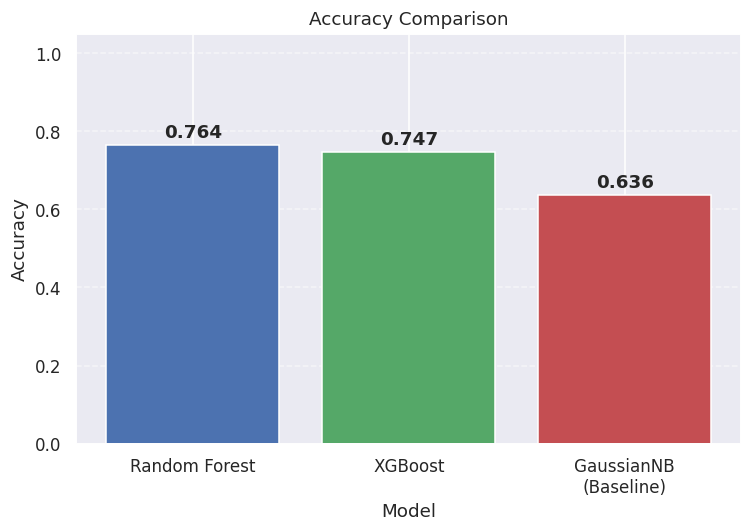

In [ ]:
results = pd.concat([nb_evaluation,rf_evaluation,xgb_evaluation])
results = results.sort_values(by='accuracy',ascending=False).round(3)
print(results.to_string())

# MODEL COMPARISON — ALL METRICS
metrics_to_plot = ['accuracy','roc_auc','pr_auc','mcc','recall','f1']
metrics_to_plot = [m for m in metrics_to_plot if m in results.columns]

plot_df = results[metrics_to_plot]
fig, ax = plt.subplots(figsize=(10, 5))
plot_df.plot(kind='bar',ax=ax,colormap='Set2')
ax.axhline(0,color='black',linewidth=0.8)
ax.set_title('Model Comparison — Naive Bayes Baseline vs. Random Forest vs. XGBoost')
ax.set_ylabel('Score')
ax.set_xlabel('Model')

# Fix long model names
label_mapping = {'Random Forest': 'Random Forest','XGBoost': 'XGBoost',
                 'GaussianNB (Baseline)': 'GaussianNB\n(Baseline)','Naive Bayes (Baseline)': 'Naive Bayes\n(Baseline)'}

labels = [label_mapping.get(str(x), str(x))for x in plot_df.index]
ax.set_xticks(range(len(plot_df.index)))
ax.set_xticklabels(labels,rotation=0,ha='center')
plt.tight_layout()
plt.legend(bbox_to_anchor=(1.02, 1),loc='upper left')
plt.show()

# BAR CHART FOR ACCURACY COMPARISON
accuracy = results[['accuracy']].sort_values(by='accuracy',ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(accuracy.index,accuracy['accuracy'],color=['#4C72B0','#55A868','#C44E52'][:len(accuracy)])
ax.set_title('Accuracy Comparison')
ax.set_ylabel('Accuracy')
ax.set_xlabel('Model')

# Fix long model names
labels = [label_mapping.get(str(x), str(x))for x in accuracy.index]
ax.set_xticks(range(len(accuracy.index)))
ax.set_xticklabels(labels,rotation=0,ha='center')
ax.set_ylim(0,1.05)
ax.grid(axis='y',linestyle='--',alpha=0.5)

# Display accuracy values above each bar
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2,height + 0.01,f'{height:.3f}',ha='center',va='bottom',fontweight='bold')

plt.tight_layout()
plt.show()

<a id='save'></a>
## Step 10 | Save Models

In [ ]:
# ============ Save Models ============
import joblib
import os

save_dir = '/content/drive/MyDrive/Colab Notebooks/dataset/models/'
os.makedirs(save_dir, exist_ok=True)

joblib.dump(best_nb, os.path.join(save_dir, 'naive_bayes_baseline_model.pkl'))
joblib.dump(best_rf, os.path.join(save_dir, 'random_forest_model.pkl'))
best_xgb.named_steps['clf'].save_model(os.path.join(save_dir, 'xgboost_model.json'))
joblib.dump(list(X_train_final.columns), os.path.join(save_dir, 'feature_columns.pkl'))

# Preprocessing artifacts
joblib.dump(ohe, os.path.join(save_dir, 'onehot_encoder.pkl'))
joblib.dump(standard_scaler, os.path.join(save_dir, 'standard_scaler.pkl'))

# Evaluation results
results.to_csv(os.path.join(save_dir, 'model_evaluation_results.csv'))

print(f'Models and preprocessing artifacts saved to: {save_dir}')
print(os.listdir(save_dir))

Models and preprocessing artifacts saved to: /content/drive/MyDrive/Colab Notebooks/dataset/models/
['naive_bayes_baseline_model.pkl', 'random_forest_model.pkl', 'xgboost_model.json', 'feature_columns.pkl', 'onehot_encoder.pkl', 'standard_scaler.pkl', 'model_evaluation_results.csv']
